# Anti-Spoofing (Liveness) Data: Loading and Exploratory Data Analysis

**COS30082 Applied Machine Learning** · Swinburne University of Technology
**Group project:** Facial Recognition with Emotion and Liveness
**Notebook:** `backend_core/training/anti_spoofing/anti_spoofing_eda.ipynb`

---

# Introduction

## Course introduction

This notebook belongs to the group project of **COS30082 Applied Machine Learning**. The project builds a camera-based attendance system with three models:

| Model | Question it answers | Data |
|---|---|---|
| Face recognition (verification) | Who is this person? | `Face Recognition` data |
| Emotion recognition | How does the face look? | `Emotion Detection` data |
| Liveness (anti-spoofing) | Is this a real, live face? | `Anti-Spoofing` data (**this notebook**) |

The liveness model is a **binary image classifier**: it receives one face image and decides whether it is a **real** person in front of the camera or a **spoof**, that is a photo or a video of a person shown to the camera on a screen. This notebook documents how the data is loaded and labelled and checks its quality before any model is trained.

**Group members:** Le Xuan Ny, Pahan Pathirathna, Nguyen Quang Khai, Pham Dinh Duc Anh, Pham Nguyen Minh Hoang, Truong Ngoc Gia Hieu.

## About this file

**Purpose.** Load the anti-spoofing dataset from Google Drive, assign a numeric label to every image, and audit the data so the team can decide cleaning, splitting and augmentation rules before training.

**What it does not do.** It trains no model and changes no data on Drive. Nothing here identifies a person.

**Questions the EDA answers**

1. How many images are there, and how many per class (real / spoof) and per split?
2. Is the dataset balanced? A liveness model that sees mostly spoofs can learn to say "spoof" for everything.
3. What are the image sizes, formats and colour modes? Are any files corrupted, dark, blurry or low-contrast?
4. **Shortcut check.** Do real and spoof images differ in simple things such as image size, file size, sharpness or brightness? A model can learn those shortcuts instead of real liveness cues, and then fail on new cameras.
5. Who and what is in the data: how many people (subjects), cameras and attack devices, and how many frames per video?
6. Are there duplicate images, the same picture under both labels (label noise), or the same picture or the same person in different splits (leakage)?

## How this notebook is organised

- **Every code cell does exactly one job** (one import block, one check, one `def`, one table, one chart). Its first line is a comment such as `# CELL 7: Configuration: outputs`. Comments inside the code explain each step.
- **Every code cell is followed by an explanation cell** with the same number: what the cell does, what goes in and out, what to check, and what to look at first if it fails.
- Cells depend on the ones above, so run them **from top to bottom**.
- All settings (paths, thresholds) are in the configuration cells near the top.

## Notebook structure

| Part | Section | Content |
|---|---|---|
| Introduction | Setup and configuration | Packages, libraries, Google Drive, settings, helper functions |
| **Part A** Data Loading and Assigning | 1.1 Locate the data | Find the dataset, check it exists, unzip if a zip is available |
| | 1.2 Load and label | List every image, read the file name, assign a label, save the inventory |
| **Part B** EDA | 2.1 Class distribution | Real and spoof per split, imbalance, class weights |
| | 2.2 Image quality | Size, format, brightness, contrast, sharpness, extreme images |
| | 2.3 Real versus spoof | Simple differences between the two classes, shortcut check, sample images |
| | 2.4 People, cameras and videos | Subjects, devices, frames per video |
| | 2.5 Duplicates and label noise | Identical and near-identical images, conflicting labels |
| | 2.6 Leakage between splits | Shared images and shared people between train, validation and test |
| | 2.7 Summary and handoff | Written summary, HTML report, copy to Drive |

## Dataset at a glance

```
Anti-Spoofing/
├── LCC_FASD_training/     real/*.png   spoof/*.png     training split
├── LCC_FASD_development/  real/*.png   spoof/*.png     validation split
└── LCC_FASD_evaluation/   real/*.png   spoof/*.png     test split
```

This is the **LCC FASD** (Large Crowd-sourced Face Anti-Spoofing Dataset) layout. The data **already has a validation split** (`development`), so none is created here. Each file name carries information: a real image is called like `YOUTUBE_id42_s1_68.png` (source, person number, session, frame number) and a spoof image like `YOUTUBE_SSMP2250_LVP1M_id39_s1_52.png`, where the extra middle part names the devices used for the attack. Section 1.2 reads this information from the names.

## How to run in Google Colab

1. Upload this notebook to Colab and choose **Runtime, Change runtime type, CPU**.
2. In Google Drive, open the shared **Anti-Spoofing** folder and choose **Organize, Add shortcut, My Drive**.
3. Run the cells from top to bottom. Allow access to Google Drive when asked.
4. If a `.zip` of the dataset is in your My Drive, the notebook copies it to the Colab disk and unzips it there (fast). Otherwise it reads from Drive and scans a 10% to 20% sample by default; change `SCAN_FRACTION` in the analysis-settings cell to scan everything.
5. All tables, charts and reports are written to `eda_outputs/` and copied to `My Drive/anti_spoofing_eda/`.

Before committing this notebook to GitHub, clear all outputs (Edit, Clear all outputs).

## Setup and configuration

In [1]:
# CELL 1: Install packages
# Install the package Colab does not ship with (-q = quiet output)
%pip -q install imagehash

**Explanation of Cell 1: Install packages**

- **Purpose:** install `imagehash`, which makes a *perceptual hash* (a short fingerprint that survives resizing and re-saving) used to find near-duplicate images.
- **Output:** nothing visible. A red pip warning about versions is normal.
- **If it fails:** check the Colab internet connection and run again. If `import imagehash` fails later, restart the runtime and run from Cell 1.

In [2]:
# CELL 2: Library loading
# --- standard library ---
import os, re, math, shutil, hashlib, base64, html, subprocess   # files, text patterns, maths, copying, hashing, HTML, shell
from pathlib import Path                                         # safe file paths: Path('a') / 'b'
from concurrent.futures import ThreadPoolExecutor                # read many images at the same time

# --- data and plotting ---
import numpy as np                  # arrays and statistics
import pandas as pd                 # tables (DataFrame)
import matplotlib.pyplot as plt     # charts and image grids

# --- images ---
import cv2                          # OpenCV: sharpness (Laplacian), colour conversion
from PIL import Image               # open images, read size / format / colour mode
import imagehash                    # perceptual hash (near-duplicate detection)

# --- display helpers ---
from tqdm.auto import tqdm          # progress bars
from IPython.display import display # show a table inside a cell that also plots or prints

**Explanation of Cell 2: Library loading**

- **Purpose:** import every library in one place so a missing library is found immediately. Nothing else happens here.

| Library | What we use it for |
|---|---|
| `os`, `shutil`, `subprocess`, `pathlib` | list, copy and unzip files; build paths |
| `re` | read information (person, session, frame) from file names |
| `hashlib` | MD5 hash of the file bytes: identical files give identical hashes |
| `math` | grid sizes |
| `base64`, `html` | build the single-file HTML report |
| `ThreadPoolExecutor` | read many images in parallel |
| `numpy`, `pandas` | numbers and tables |
| `matplotlib.pyplot` | charts and image grids |
| `cv2` | sharpness measure and colour saturation |
| `PIL.Image` | open images |
| `imagehash` | perceptual hash |
| `tqdm`, `display` | progress bars, show tables |

- **If it fails:** `ModuleNotFoundError` means Cell 1 was not run. Run Cell 1, restart the runtime, then run this cell.

In [3]:
# CELL 3: Google Drive connection
# Try to mount Google Drive (only works inside Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')   # a pop-up asks for permission
    IN_COLAB = True
except ImportError:
    IN_COLAB = False                # running on a laptop: no Drive

print('running in Colab:', IN_COLAB)

Mounted at /content/drive
running in Colab: True


**Explanation of Cell 3: Google Drive connection**

- **Purpose:** connect Google Drive to Colab so the dataset can be read and results saved.
- **In Colab:** allow access in the pop-up. Drive then appears at `/content/drive/MyDrive`.
- **Outside Colab:** the import fails, `IN_COLAB` is `False`, and local paths are used.
- **Variable created:** `IN_COLAB`.
- **If it fails:** allow pop-ups for colab.research.google.com. `Mounted at /content/drive` means success.

In [4]:
# CELL 4: Configuration: data location
DATA_FOLDER_NAME = 'Anti-Spoofing'  # name of the shared folder (or of your shortcut to it) in My Drive
ZIP_PATH = None                     # full path of a dataset .zip, or None = search for one
USE_ZIP = 'auto'                    # 'auto' = use a zip if found | True = require one | False = never

**Explanation of Cell 4: Configuration: data location**

- **Purpose:** tell the notebook where the dataset is. Change values here only.
- **`DATA_FOLDER_NAME`**: folder name as shown in My Drive. If you renamed your shortcut, change it here.
- **`ZIP_PATH`**: `None` lets the notebook look for a `.zip`; or give a path like `'/content/drive/MyDrive/anti_spoofing.zip'`.
- **`USE_ZIP`**: `'auto'` uses a zip when one exists; `True` stops with an error if none; `False` always reads Drive directly.
- **Output:** none.

In [5]:
# CELL 5: Configuration: dataset layout
# split name -> folder (relative to the dataset root); each folder has one sub-folder per class
SPLITS = {
    'train': 'LCC_FASD_training',
    'val':   'LCC_FASD_development',
    'test':  'LCC_FASD_evaluation',
}
# class folder name -> class number (1 = real / live is the "positive" class)
LABEL_MAP = {'spoof': 0, 'real': 1}
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}   # file extensions counted as images

**Explanation of Cell 5: Configuration: dataset layout**

- **Purpose:** describe how the dataset folder is organised.
- **`SPLITS`**: split name to folder. The key becomes the `split` column in every table. This dataset **already has a validation split** (`development`).
- **`LABEL_MAP`**: the class number given to each class folder: `spoof` = 0 and `real` = 1. Real is the positive class, so "recall of real faces" and "rejection of spoofs" are easy to read later.
- **`IMG_EXT`**: other files are skipped and counted.
- **Output:** none. Change only if the folder structure changes.

In [6]:
# CELL 6: Configuration: analysis settings and thresholds
SEED = 42               # fixed random seed: same "random" samples on every run
SCAN_FRACTION = None    # share of images scanned: None = 1.0 with a zip, 0.1 from Drive

# Starting thresholds, to be confirmed with the charts and grids in Part B
LOW_RES_PX = 128        # shortest side below this = low resolution
BLUR_THR = 50.0         # sharpness (Laplacian variance at 224 px) below this = blurry
DARK, BRIGHT = 40, 210  # mean grey level below DARK = too dark, above BRIGHT = too bright
LOW_CONTRAST = 20       # grey-level std below this = low contrast
SHORTCUT_AUC = 0.70     # a simple feature that separates real from spoof better than this is a shortcut risk
N_PER_CLASS_GRID = 12   # sample images shown per class
N_MEAN_IMAGE = 300      # images averaged to build the "average image" of each class

**Explanation of Cell 6: Configuration: analysis settings and thresholds**

- **Purpose:** keep every tunable number in one cell.
- **`SEED`**: makes samples repeatable between teammates.
- **`SCAN_FRACTION`**: share of images opened by the quality scan. `1.0` = all, `0.1` = random 10%, `None` = decided automatically later.
- **Thresholds** are *starting values*. Sharpness is measured after resizing every image to 224 x 224, so images of different sizes can be compared. Confirm the thresholds with the charts and grids before using them to remove data.
- **`SHORTCUT_AUC`**: in section 2.3, a simple measurement (for example sharpness) with an AUC above this value separates real from spoof too easily. 0.5 means no separation, 1.0 means perfect separation.
- **`N_PER_CLASS_GRID`, `N_MEAN_IMAGE`**: sizes of the visual checks in section 2.3.

In [7]:
# CELL 7: Configuration: outputs
# Local output folder on the Colab disk (EDA_OUT env variable overrides it for local runs)
OUT = Path(os.environ.get('EDA_OUT', 'eda_outputs'))
OUT.mkdir(parents=True, exist_ok=True)

# Folder in My Drive where results are copied at the end (None outside Colab)
SAVE_TO = Path('/content/drive/MyDrive/anti_spoofing_eda') if IN_COLAB else None

np.random.seed(SEED)    # make numpy randomness repeatable
print('results are written to:', OUT.resolve())
print('copied to Drive at    :', SAVE_TO)

results are written to: /content/eda_outputs
copied to Drive at    : /content/drive/MyDrive/anti_spoofing_eda


**Explanation of Cell 7: Configuration: outputs**

- **Purpose:** decide where results are saved.
- **`OUT`**: local folder `eda_outputs/` (deleted when the Colab session ends).
- **`SAVE_TO`**: folder in My Drive; the last cell copies everything there so results survive.
- **Output:** two printed paths.

In [8]:
# CELL 8: Helper function: savefig
def savefig(name):
    plt.tight_layout()                                              # avoid overlapping labels
    plt.savefig(OUT / f'{name}.png', dpi=120, bbox_inches='tight')  # save the PNG
    plt.show()                                                      # then show it

**Explanation of Cell 8: Helper function: savefig**

- **Purpose:** save the current chart as a PNG in `OUT` and show it.
- **Argument:** `name`, file name without `.png`.
- **Used by:** every chart cell and `show_grid`.
- **Output:** none (defines the function only).

In [9]:
# CELL 9: Helper function: show_grid
def show_grid(paths, title, name, ncols=8, labels=None):
    paths = list(paths)
    if not paths:                                        # nothing to draw
        print(f'{title}: nothing to show')
        return
    # default caption = class folder name
    labels = list(labels) if labels is not None else [Path(p).parent.name for p in paths]
    nrows = math.ceil(len(paths) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.6, nrows * 1.9), squeeze=False)
    for ax in axes.ravel():                              # hide all axes first
        ax.axis('off')
    for ax, p, lab in zip(axes.ravel(), paths, labels):
        try:
            with Image.open(p) as im:
                im = im.convert('RGB')
                im.thumbnail((256, 256))                 # shrink big photos: faster, same look
                ax.imshow(im)                            # draw the image in colour
            ax.set_title(str(lab), fontsize=6)           # small caption
        except Exception:
            ax.set_title('unreadable', fontsize=6)       # a broken file must not stop the grid
    fig.suptitle(title)
    savefig(name)

**Explanation of Cell 9: Helper function: show_grid**

- **Purpose:** draw many images in a grid so a person can look at them. Numbers cannot show a mislabelled or unusual image.
- **Arguments:** `paths`, `title`, `name` (PNG name), `ncols` (default 8), `labels` (caption under each image; default = class folder name).
- **Behaviour:** images are shrunk to at most 256 px for speed; unreadable images show `unreadable`; an empty list prints "nothing to show".
- **Output:** none (defines the function only).

In [10]:
# CELL 10: Helper function: scan_image
def scan_image(path):
    """Measure ONE image and return a dictionary."""
    rec = {'path': path}
    try:
        raw = Path(path).read_bytes()
        rec['bytes'] = len(raw)                            # file size on disk
        rec['md5'] = hashlib.md5(raw).hexdigest()          # identical files -> identical hash
        with Image.open(path) as im:
            rec['format'], rec['mode'] = im.format, im.mode
            rec['width'], rec['height'] = im.size
            im.load()                                      # force full decode (detects truncated files)
            rec['phash'] = str(imagehash.phash(im.convert('RGB')))   # perceptual hash (near copies)
            rgb = np.asarray(im.convert('RGB'))
        grey = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
        rec['brightness'] = float(grey.mean())             # mean grey level
        rec['contrast'] = float(grey.std())                # spread of grey levels
        small = cv2.resize(grey, (224, 224), interpolation=cv2.INTER_AREA)   # same size for every image
        rec['blur'] = float(cv2.Laplacian(small, cv2.CV_32F).var())          # low = blurry
        rec['saturation'] = float(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)[..., 1].mean())   # 0 = grey, 255 = vivid colour
        rec['bytes_per_pixel'] = rec['bytes'] / (rec['width'] * rec['height'])   # compression / detail level
        rec['corrupt'] = False
    except Exception as e:                                 # never stop the whole scan for one bad file
        rec['corrupt'] = True
        rec['error'] = f'{type(e).__name__}: {e}'[:120]
    return rec

**Explanation of Cell 10: Helper function: scan_image**

- **Purpose:** open **one** image and measure everything the EDA needs.

| Key | Meaning | Used for |
|---|---|---|
| `md5` | hash of the file bytes | identical-file duplicates, leakage |
| `phash` | perceptual hash | near duplicates |
| `format`, `mode`, `width`, `height`, `bytes` | file facts | size and format tables, shortcut check |
| `brightness`, `contrast` | grey-level mean / spread | lighting, low-contrast flag |
| `blur` | Laplacian variance at 224 px (low = blurry) | blur flag, shortcut check |
| `saturation` | average colour strength (0 to 255) | colour differences between classes |
| `bytes_per_pixel` | file size divided by pixel count | compression, shortcut check |
| `corrupt`, `error` | could not be read, and why | corrupted-file list |

- **Why resize for sharpness:** the Laplacian grows with image size, so every image is shrunk to 224 x 224 first. Otherwise a large image would always look "sharper".
- **Safety:** all errors are caught, so one broken file never stops the scan.
- **Output:** none (defines the function only).

In [11]:
# CELL 11: Helper function: scan_many
def scan_many(df, fraction, desc):
    # choose all images or a random sample
    part = df if fraction >= 1 else df.sample(frac=fraction, random_state=SEED)
    # measure them in parallel (16 threads; reading files mostly waits for the disk)
    with ThreadPoolExecutor(max_workers=16) as ex:
        recs = list(tqdm(ex.map(scan_image, part.path), total=len(part), desc=desc))
    # join the measurements back onto the original table (keeps split / class columns)
    res = part.merge(pd.DataFrame(recs), on='path')
    if 'error' not in res:
        res['error'] = None
    res['short_side'] = res[['width', 'height']].min(axis=1)   # smaller side, for the low-res flag
    return res

**Explanation of Cell 11: Helper function: scan_many**

- **Purpose:** run `scan_image` on many images at once and return one table.
- **Arguments:** `df` (table with a `path` column), `fraction` (1.0 = all, 0.1 = random 10%), `desc` (progress-bar text).
- **Adds:** `short_side`, the smaller of width and height.
- **Output:** none (defines the function only).

In [12]:
# CELL 12: Helper function: fmt_int
def fmt_int(x):
    # 28709 -> '28,709'; missing values -> '0'
    return '0' if pd.isna(x) else f'{int(x):,}'

**Explanation of Cell 12: Helper function: fmt_int**

- **Purpose:** format numbers with thousands separators for the written summary. Missing values become `0`.
- **Output:** none (defines the function only).

In [13]:
# CELL 13: Helper function: parse_name
# Pattern of an LCC FASD file name, for example
#   real :  YOUTUBE_id42_s1_68.png
#   spoof:  YOUTUBE_SSMP2250_LVP1M_id39_s1_52.png   (the middle part names the attack devices)
NAME_RE = re.compile(r'^(?P<source>[^_]+)_(?:(?P<device>.+)_)?id(?P<pid>\d+)_s(?P<session>\d+)_(?P<frame>\d+)$', re.I)

def parse_name(stem):
    m = NAME_RE.match(stem)
    if not m:                                           # a file that does not follow the pattern
        return {'source': None, 'device': None, 'person': None, 'session': None, 'frame': None}
    g = m.groupdict()
    return {'source': g['source'],                      # where the video came from, e.g. YOUTUBE
            'device': g['device'] or 'none',            # attack devices (spoof only); 'none' for real images
            'person': f"{g['source']}_id{g['pid']}",    # one person (subject)
            'session': int(g['session']),               # recording session of that person
            'frame': int(g['frame'])}                   # frame number inside the video

**Explanation of Cell 13: Helper function: parse_name**

- **Purpose:** read information from a file name. The names of this dataset carry the person, the session and the frame number, and spoof names also name the attack devices. This lets us count people and videos without opening a single image.
- **Argument:** `stem`, the file name without extension.
- **Returns:** a dictionary with `source`, `device`, `person`, `session`, `frame`. Names that do not match the pattern give `None` values, and the next cells count them.
- **Output:** none (defines the function only).

---
# Part A: Data Loading and Assigning

Part A turns the folders on Google Drive into one table with a row per image: its split, its class (real or spoof), a numeric **class label** (0 or 1) and the information in its file name. Nothing is modified on Drive.

## 1.1 Locate the data

In [14]:
# CELL 14: Function: find_data_root
def find_data_root():
    first_split = next(iter(SPLITS.values()))             # one split folder is enough to recognise the dataset
    # 1) explicit path from the environment (used for local runs)
    env = os.environ.get('SPOOF_DATA')
    if env and (Path(env) / first_split).exists():
        return Path(env)
    # 2) the folder or shortcut directly in My Drive
    default = Path('/content/drive/MyDrive') / DATA_FOLDER_NAME
    if (default / first_split).exists():
        return default
    # 3) search one or two levels below My Drive and in "shared with me" shortcut targets
    roots = [Path('/content/drive/MyDrive'), Path('/content/drive/.shortcut-targets-by-id')]
    for r in roots:
        for pat in (DATA_FOLDER_NAME, f'*/{DATA_FOLDER_NAME}', f'*/*/{DATA_FOLDER_NAME}'):
            for p in r.glob(pat):
                if (p / first_split).exists():           # accept only the real dataset
                    return p
    return None

**Explanation of Cell 14: Function: find_data_root**

- **Purpose:** find the dataset folder wherever your shortcut ended up.
- **Search order:** `SPOOF_DATA` environment variable, then `My Drive/<DATA_FOLDER_NAME>`, then up to two levels below My Drive and the shared-shortcut folder.
- A folder is accepted only if it contains the training split folder.
- **Returns:** a `Path`, or `None`.
- **Output:** none (defines the function only).

In [15]:
# CELL 15: Locate the dataset folder on Drive
# Run the search defined above
DATA_ROOT = find_data_root()
print('dataset folder on Drive:', DATA_ROOT)

dataset folder on Drive: /content/drive/MyDrive/Facial_Recognition_with_Emotion_and_Liveliness/Anti-Spoofing


**Explanation of Cell 15: Locate the dataset folder on Drive**

- **Purpose:** call `find_data_root` and keep the result in `DATA_ROOT`.
- **Output:** the folder path, or `None` if nothing was found (the next cell decides whether that is an error).

In [16]:
# CELL 16: Check that the dataset exists
# Stop early, with a clear message, if the dataset cannot be reached
if DATA_ROOT is None and USE_ZIP is not True:
    raise FileNotFoundError(
        f'Could not find a folder named "{DATA_FOLDER_NAME}" containing {list(SPLITS.values())}. '
        'In Google Drive, right-click the shared folder, choose Organize, Add shortcut, My Drive, '
        'then run the "Locate the dataset folder" cell again (or set DATA_FOLDER_NAME / ZIP_PATH).')

# Show whether each expected item is present
if DATA_ROOT is not None:
    for item in SPLITS.values():
        print(('OK      ' if (DATA_ROOT / item).exists() else 'MISSING ') + item)

OK      LCC_FASD_training
OK      LCC_FASD_development
OK      LCC_FASD_evaluation


**Explanation of Cell 16: Check that the dataset exists**

- **Purpose:** the existence check. It stops with a clear message when the dataset is not reachable, and lists which split folders are present.
- **Output:** one line per split folder, `OK` or `MISSING`.
- **If it raises `FileNotFoundError`:** in Google Drive right-click the shared **Anti-Spoofing** folder, choose **Organize, Add shortcut, My Drive**, then run the locate cell again. If your shortcut has another name, change `DATA_FOLDER_NAME` in the data-location cell.

In [17]:
# CELL 17: Look for a dataset zip file
zip_file = None
if USE_ZIP is not False:
    if ZIP_PATH:                                           # explicit path wins
        zip_file = Path(ZIP_PATH)
    elif IN_COLAB:
        found = []
        for folder in [DATA_ROOT, Path('/content/drive/MyDrive')]:
            if folder is not None and folder.exists():
                found += list(folder.glob('*.zip'))        # any zip in these two folders
        if found:
            zip_file = max(found, key=lambda p: p.stat().st_mtime)   # newest one
    if USE_ZIP is True and zip_file is None:
        raise FileNotFoundError('USE_ZIP is True but no .zip was found. Set ZIP_PATH by hand.')

print('zip file:', zip_file)

zip file: None


**Explanation of Cell 17: Look for a dataset zip file**

- **Purpose:** decide whether the dataset will be read from a zip (fast) or straight from Drive (slow).
- **Why a zip:** Drive is slow with tens of thousands of image files; one zip is copied to the Colab disk in a single transfer.
- **Variable created:** `zip_file` (`Path` or `None`).
- **Output:** the zip path, or `None` (then the notebook reads from Drive).

In [18]:
# CELL 18: Choose the load mode
# 'zip' = copy + unzip to the Colab disk, 'drive' = read in place
LOAD_MODE = 'zip' if zip_file is not None else 'drive'
DATA_DIR = Path('/content/spoof_zip_data')   # where the zip is unzipped
print('load mode:', LOAD_MODE)

load mode: drive


**Explanation of Cell 18: Choose the load mode**

- **Purpose:** record the decision as one variable, `LOAD_MODE`, used by the next cells.
- **`DATA_DIR`**: folder on the Colab disk used only in zip mode.
- **Output:** `zip` or `drive`.

In [19]:
# CELL 19: Copy and unzip the dataset (zip mode only)
if LOAD_MODE == 'zip':
    print(f'using {zip_file.name} ({zip_file.stat().st_size / 1e9:.2f} GB)')
    if not (DATA_DIR / '.unzipped').exists():              # skip if already unzipped in this session
        shutil.rmtree(DATA_DIR, ignore_errors=True)
        DATA_DIR.mkdir(parents=True)
        local_zip = Path('/content/dataset.zip')
        shutil.copy(zip_file, local_zip)                   # one big file copies quickly
        subprocess.run(['unzip', '-q', '-o', str(local_zip), '-d', str(DATA_DIR)], check=True)
        local_zip.unlink()                                 # free disk space
        (DATA_DIR / '.unzipped').touch()                   # marker: done
    else:
        print('already unzipped, skipping')
else:
    print('drive mode: nothing to unzip')

drive mode: nothing to unzip


**Explanation of Cell 19: Copy and unzip the dataset (zip mode only)**

- **Purpose:** copy the zip to the Colab disk and unzip it there. Does nothing in drive mode.
- **Marker file:** `.unzipped` lets a re-run skip the slow part.
- **If it fails:** `No space left on device` means the Colab disk is full (this dataset has large images); restart the session or use drive mode.

In [20]:
# CELL 20: Set the dataset root (ROOT)
first_split = next(iter(SPLITS.values()))
if LOAD_MODE == 'zip':
    # the zip may wrap everything in an extra folder, so find where the training folder sits
    hits = [p.parent for p in DATA_DIR.rglob(first_split) if p.is_dir()]
    assert hits, f'{first_split} folder not found inside the zip'
    ROOT = min(hits, key=lambda p: len(p.parts))          # the shallowest match
else:
    ROOT = DATA_ROOT                                       # read directly from Drive

print('dataset root:', ROOT)
print('contents    :', sorted(os.listdir(ROOT)))

dataset root: /content/drive/MyDrive/Facial_Recognition_with_Emotion_and_Liveliness/Anti-Spoofing
contents    : ['LCC_FASD_development', 'LCC_FASD_evaluation', 'LCC_FASD_training']


**Explanation of Cell 20: Set the dataset root (ROOT)**

- **Purpose:** set `ROOT`, the folder that contains the three split folders. Every later cell uses it.
- **Output:** the root path and its contents (expect the three `LCC_FASD_...` folders).
- **If it fails:** `folder not found inside the zip` means the zip has another layout. Open it and check.

In [21]:
# CELL 21: Set the scan size
# None -> 100% when a zip is used (fast disk), 10% when reading from Drive (slow, large images)
if SCAN_FRACTION is None:
    SCAN_FRACTION = 1.0 if LOAD_MODE == 'zip' else 0.1

print(f'quality scan covers {SCAN_FRACTION:.0%} of the images')
if LOAD_MODE == 'drive':
    print('Reading straight from Drive is slow. Put a zip of the dataset in My Drive for a full, fast run.')

quality scan covers 10% of the images
Reading straight from Drive is slow. Put a zip of the dataset in My Drive for a full, fast run.


**Explanation of Cell 21: Set the scan size**

- **Purpose:** fix the final value of `SCAN_FRACTION`.
- **Output:** the percentage used by the quality scan.
- **Why 10%:** these images are large (hundreds of KB each), so reading them from Drive is slower than for the small face crops of the other datasets.
- **Tip:** to scan everything from Drive anyway, set `SCAN_FRACTION = 1.0` in the analysis-settings cell. The file-name analysis in section 2.4 never needs the scan and always covers every image.

## 1.2 Load and label

In [22]:
# CELL 22: List the images
rows, skipped = [], []                       # rows = images found, skipped = non-image files
for split, rel in SPLITS.items():
    base = ROOT / rel
    # every sub-folder of a split is one class (real / spoof)
    classes = sorted(e.name for e in os.scandir(base) if e.is_dir())
    for cls in tqdm(classes, desc=split):
        with os.scandir(base / cls) as it:
            for e in it:
                if Path(e.name).suffix.lower() in IMG_EXT:
                    rows.append((split, cls, e.path))     # keep (split, class, file path)
                else:
                    skipped.append(e.path)
print(f'{len(rows):,} image files found | {len(skipped)} non-image files skipped')

train:   0%|          | 0/2 [00:00<?, ?it/s]

val:   0%|          | 0/2 [00:00<?, ?it/s]

test:   0%|          | 0/2 [00:00<?, ?it/s]

18,827 image files found | 0 non-image files skipped


**Explanation of Cell 22: List the images**

- **Purpose:** walk the split folders and collect every image file.
- **Variables created:** `rows` (split, class, path) and `skipped` (non-image files).
- **Output:** progress bar per split, then the counts.
- **If it fails:** `FileNotFoundError` for a split folder means `SPLITS` (layout cell) does not match the real folder names.

In [23]:
# CELL 23: Build the image table
# One row per image
img_df = pd.DataFrame(rows, columns=['split', 'cls', 'path'])
img_df['ext'] = img_df.path.str.rsplit('.', n=1).str[-1].str.lower()   # file extension
img_df.head()

,split,cls,path,ext
0,train,real,/content/drive/MyDrive/Facial_Recognition_with...,png
1,train,real,/content/drive/MyDrive/Facial_Recognition_with...,png
2,train,real,/content/drive/MyDrive/Facial_Recognition_with...,png
3,train,real,/content/drive/MyDrive/Facial_Recognition_with...,png
4,train,real,/content/drive/MyDrive/Facial_Recognition_with...,png


**Explanation of Cell 23: Build the image table**

- **Purpose:** turn `rows` into the main table `img_df`, **one row per image**.
- **Columns:** `split`, `cls` (class folder: real or spoof), `path`, `ext`.
- **Output:** the first five rows.

In [24]:
# CELL 24: Read the information in the file names
# file name without folder and extension -> person, session, frame, source, attack devices
meta = pd.DataFrame([parse_name(Path(p).stem) for p in img_df.path], index=img_df.index)
img_df = pd.concat([img_df, meta], axis=1)

n_bad = int(img_df.person.isna().sum())
print(f'{n_bad} file names do not follow the pattern')
img_df.head()

7580 file names do not follow the pattern


,split,cls,path,ext,source,device,person,session,frame
0,train,real,/content/drive/MyDrive/Facial_Recognition_with...,png,YOUTUBE,none,YOUTUBE_id104,0.0,135.0
1,train,real,/content/drive/MyDrive/Facial_Recognition_with...,png,SMG950U,none,SMG950U_id130,0.0,179.0
2,train,real,/content/drive/MyDrive/Facial_Recognition_with...,png,YOUTUBE,none,YOUTUBE_id102,0.0,150.0
3,train,real,/content/drive/MyDrive/Facial_Recognition_with...,png,YOUTUBE,none,YOUTUBE_id101,0.0,105.0
4,train,real,/content/drive/MyDrive/Facial_Recognition_with...,png,YOUTUBE,none,YOUTUBE_id104,0.0,120.0


**Explanation of Cell 24: Read the information in the file names**

- **Purpose:** add `source`, `device`, `person`, `session` and `frame` to every row, using `parse_name`.
- **Output:** the number of file names that do **not** follow the pattern (expect 0), then the first rows.
- **If the count is large:** the naming pattern in the `parse_name` cell does not fit this copy of the dataset. Person and video analysis (section 2.4) then covers only the images that matched.

In [25]:
# CELL 25: Count images per split and class
# rows = splits, columns = classes
counts = pd.crosstab(img_df.split, img_df.cls).reindex(index=list(SPLITS))
counts['total'] = counts.sum(axis=1)
counts.loc['TOTAL'] = counts.sum()
counts

cls,real,spoof,total
split,,,
train,1223,7076,8299
val,405,2543,2948
test,314,7266,7580
TOTAL,1942,16885,18827


**Explanation of Cell 25: Count images per split and class**

- **Purpose:** the first sanity check: how many real and spoof images each split has.
- **What to check:** every split should contain both classes. A missing class in one split means a partial upload.

In [26]:
# CELL 26: Assign the label to every image
unknown = set(img_df.cls) - set(LABEL_MAP)
assert not unknown, f'class folders not in LABEL_MAP: {unknown}'   # stop if a folder name is unexpected

img_df['label'] = img_df.cls.map(LABEL_MAP).astype(int)            # spoof = 0, real = 1
print(LABEL_MAP)

# Check that every split contains both classes
for s in SPLITS:
    print(s, sorted(img_df[img_df.split == s].cls.unique()))

{'spoof': 0, 'real': 1}
train ['real', 'spoof']
val ['real', 'spoof']
test ['real', 'spoof']


**Explanation of Cell 26: Assign the label to every image**

- **Purpose:** add the numeric `label` column (`spoof` = 0, `real` = 1) and check that every split has both classes.
- **Output:** the label map and, per split, the classes it contains.
- **If it fails:** an `AssertionError` names a class folder that is not in `LABEL_MAP`; add it there or fix the folder name.

In [27]:
# CELL 27: Save the inventory and the label map
# inventory: every image with split, class, label, file-name information and path
img_df.to_csv(OUT / 'spoof_inventory.csv', index=False)
# label map: class -> class number
pd.Series(LABEL_MAP, name='label').rename_axis('class').reset_index().to_csv(OUT / 'label_map.csv', index=False)
img_df.sample(5, random_state=SEED)[['split', 'cls', 'label', 'person', 'device', 'path']]   # peek at 5 random rows

,split,cls,label,person,device,path
3826,train,spoof,0,YOUTUBE_id51,IIYAMAXU_MOTOMC_S1,/content/drive/MyDrive/Facial_Recognition_with...
5350,train,spoof,0,YOUTUBE_id41,BQXL2420_NEXUS5,/content/drive/MyDrive/Facial_Recognition_with...
409,train,real,1,YOUTUBE_id46,none,/content/drive/MyDrive/Facial_Recognition_with...
4981,train,spoof,0,YOUTUBE_id67,IIYAMAXB_SMG955U,/content/drive/MyDrive/Facial_Recognition_with...
5763,train,spoof,0,YOUTUBE_id33,HP250_MEIZUM3S,/content/drive/MyDrive/Facial_Recognition_with...


**Explanation of Cell 27: Save the inventory and the label map**

- **Purpose:** save both tables so training notebooks need not scan Drive again.
- **Files:** `spoof_inventory.csv`, `label_map.csv` in `eda_outputs/`.
- **Output:** five random rows.
- **Note:** the paths are valid for **this** Colab session only; another session should rebuild paths from split, class and file name.

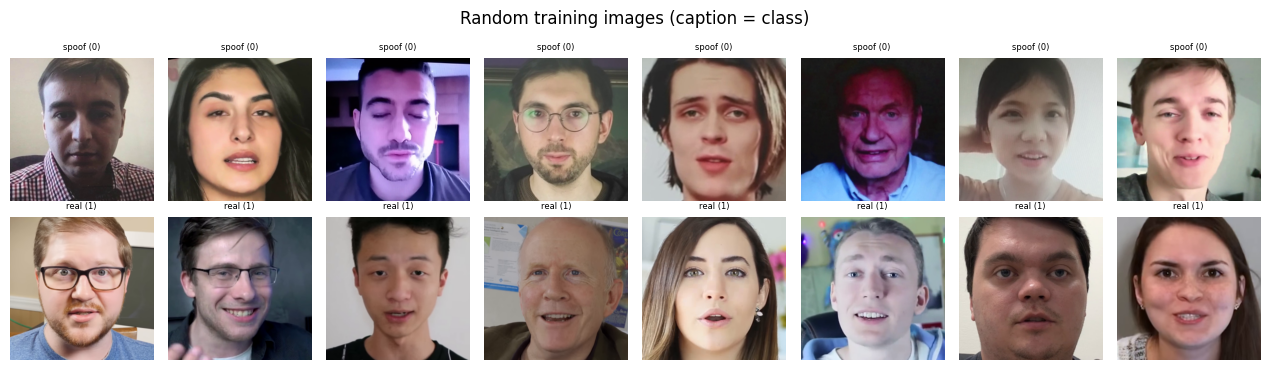

In [28]:
# CELL 28: Preview images with their labels
train_df = img_df[img_df.split == 'train']
sample = pd.concat([train_df[train_df.cls == c].sample(min(8, (train_df.cls == c).sum()), random_state=SEED)
                    for c in LABEL_MAP])                                    # 8 spoof + 8 real training images
show_grid(sample.path, 'Random training images (caption = class)', 'A1_preview',
          labels=[f'{c} ({l})' for c, l in zip(sample.cls, sample.label)])

**Explanation of Cell 28: Preview images with their labels**

- **Purpose:** look at real images with their assigned class and label.
- **Output:** a grid; each caption is `class (label)`.
- **Saved as:** `A1_preview.png`.
- **What to check:** real images show a person; spoof images show a screen, a frame or a recaptured photo. Look for anything that makes one class obviously different (see section 2.3).

---
# Part B: Exploratory Data Analysis (EDA)

Part B audits the table built in Part A. Thresholds for "blurry", "too dark" and so on are the starting values from the analysis-settings cell; confirm them with the sample grids before using them to filter data.

## 2.1 Class distribution

In [29]:
# CELL 29: Share of real and spoof images per split (percent)
# share of each class inside its own split, in percent
share = (pd.crosstab(img_df.split, img_df.cls, normalize='index') * 100).round(1).reindex(index=list(SPLITS))
share.to_csv(OUT / 'class_share_pct.csv')
share

cls,real,spoof
split,,
train,14.7,85.3
val,13.7,86.3
test,4.1,95.9


**Explanation of Cell 29: Share of real and spoof images per split (percent)**

- **Purpose:** the share of real and spoof images inside each split.
- **File:** `class_share_pct.csv`.
- **What to check:** if the shares differ a lot between train, validation and test, the validation and test scores are not measured on the same mix of data the model is trained on. A very high spoof share also means a model can score well by always answering "spoof".

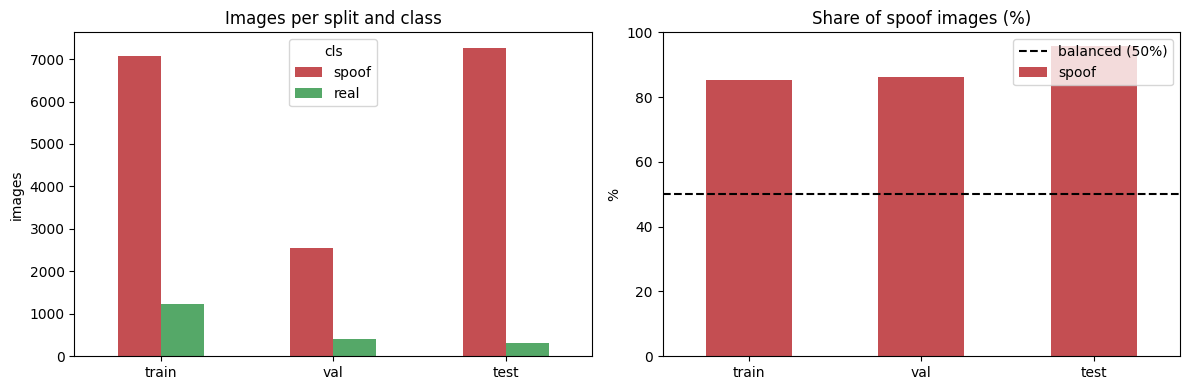

In [30]:
# CELL 30: Chart: real and spoof images per split
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# left: number of real and spoof images per split
counts.drop(index='TOTAL')[list(LABEL_MAP)].plot.bar(ax=axes[0], color=['#C44E52', '#55A868'])
axes[0].set(title='Images per split and class', ylabel='images', xlabel='')
axes[0].tick_params(axis='x', rotation=0)
# right: share of spoof images in each split, with the 50% line of a balanced set
share['spoof'].plot.bar(ax=axes[1], color='#C44E52')
axes[1].axhline(50, color='k', ls='--', label='balanced (50%)')
axes[1].set(title='Share of spoof images (%)', ylabel='%', xlabel='', ylim=(0, 100))
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend()
savefig('B1_class_distribution')

**Explanation of Cell 30: Chart: real and spoof images per split**

- **Purpose:** show the class distribution as a picture.
- **Left:** number of real and spoof images in each split.
- **Right:** share of spoof images per split. The dashed line is a perfectly balanced set (50%).
- **Saved as:** `B1_class_distribution.png`.

In [31]:
# CELL 31: Imbalance statistics
c = counts.loc['train', list(LABEL_MAP)]                    # training images per class
imbalance = pd.Series({
    'classes': len(c),
    'largest class': f'{c.idxmax()} ({c.max():,})',
    'smallest class': f'{c.idxmin()} ({c.min():,})',
    'largest / smallest (imbalance ratio)': round(c.max() / c.min(), 2),
    'smallest class share (%)': round(c.min() / c.sum() * 100, 2),
    'spoof share in train (%)': round(c['spoof'] / c.sum() * 100, 2),
}, name='value')
imbalance.to_csv(OUT / 'class_imbalance.csv')
imbalance

,value
classes,2
largest class,"spoof (7,076)"
smallest class,"real (1,223)"
largest / smallest (imbalance ratio),5.79
smallest class share (%),14.74
spoof share in train (%),85.26


**Explanation of Cell 31: Imbalance statistics**

- **Purpose:** put a number on the imbalance in the training split.
- **Imbalance ratio:** the larger class divided by the smaller. With only two classes, a ratio near 1 is balanced; a ratio of 3 or more means the model needs class weights or balanced sampling.
- **File:** `class_imbalance.csv`.

In [32]:
# CELL 32: Class weights for training
# "balanced" weight = total / (number of classes * images in the class): the rarer class gets the larger weight
class_weights = (c.sum() / (len(c) * c)).round(3).rename('weight').rename_axis('class').reset_index()
class_weights['label'] = class_weights['class'].map(LABEL_MAP)
class_weights.to_csv(OUT / 'class_weights.csv', index=False)
class_weights

,class,weight,label
0,spoof,0.586,0
1,real,3.393,1


**Explanation of Cell 32: Class weights for training**

- **Purpose:** compute a weight for each class, to be passed to the loss function during training (for example `CrossEntropyLoss(weight=...)` or `pos_weight` for a binary loss), so that errors on the rarer class count more.
- **Formula:** `total images / (number of classes x images in the class)`. A weight of 1 means "average".
- **File:** `class_weights.csv`. The training notebook can load it directly.

## 2.2 Image quality

In [33]:
# CELL 33: Scan the images
# Slowest cell: open the images and measure each one
img_df['clip'] = img_df.person.fillna('?') + '|s' + img_df.session.fillna(-1).astype(int).astype(str) + '|' + img_df.device.fillna('?')   # one video = one person, session, device
q = scan_many(img_df, SCAN_FRACTION, 'scanning images')
q.to_csv(OUT / 'image_quality.csv', index=False)
print(f'scanned {len(q):,} of {len(img_df):,} images | corrupted: {int(q.corrupt.sum())}')

scanning images:   0%|          | 0/1883 [00:00<?, ?it/s]

scanned 1,883 of 18,827 images | corrupted: 0


**Explanation of Cell 33: Scan the images**

- **Purpose:** measure the images (all, or a random `SCAN_FRACTION`).
- **Also adds** the column `clip` (person, session and devices joined together). Frames with the same `clip` come from the same video.
- **Variable:** `q` (all scanned images, including corrupted ones). **File:** `image_quality.csv`.
- **Output:** progress bar, then scanned and corrupted counts.
- **Time:** about a minute per 10,000 images with a zip, longer from Drive. If the runtime disconnects, run the cell again.

In [34]:
# CELL 34: Keep only the readable images
# ok = images that could be opened; corrupted ones are reported separately
ok = q[~q.corrupt].copy()
bad = q[q.corrupt]
print(f'readable: {len(ok):,} | corrupted: {len(bad)}')

readable: 1,883 | corrupted: 0


**Explanation of Cell 34: Keep only the readable images**

- **Purpose:** split the scan into `ok` (readable, used by all charts) and `bad` (corrupted).
- **Output:** the two counts.

In [35]:
# CELL 35: Image sizes, formats and colour modes
# most common sizes per split
size_counts = (ok.assign(size=ok.width.astype(int).astype(str) + 'x' + ok.height.astype(int).astype(str))
                 .groupby(['split', 'cls', 'size']).size().rename('images').reset_index()
                 .sort_values('images', ascending=False))
# file format + colour mode per split and class
fmt_mode = ok.groupby(['split', 'cls', 'format', 'mode']).size().rename('images').reset_index()
size_counts.to_csv(OUT / 'image_sizes.csv', index=False)
fmt_mode.to_csv(OUT / 'formats_and_modes.csv', index=False)

print('number of different sizes:', size_counts['size'].nunique())
display(size_counts.head(10))
fmt_mode

number of different sizes: 673


,split,cls,size,images
693,train,spoof,400x400,9
849,train,spoof,627x627,7
172,test,spoof,390x390,7
779,train,spoof,520x520,7
178,test,spoof,400x400,7
352,test,spoof,653x653,6
751,train,spoof,480x480,6
205,test,spoof,442x442,6
609,train,spoof,256x256,6
682,train,spoof,387x387,5


,split,cls,format,mode,images
0,test,real,PNG,RGB,27
1,test,spoof,PNG,RGB,728
2,train,real,PNG,RGB,103
3,train,spoof,PNG,RGB,702
4,val,real,PNG,RGB,51
5,val,spoof,PNG,RGB,272


**Explanation of Cell 35: Image sizes, formats and colour modes**

- **Purpose:** find which sizes, formats and colour modes exist, per class.
- **Output:** the number of different sizes, the ten most common size groups, and the format and colour-mode table.
- **What to check:** this dataset is collected from many videos, so several sizes are likely. Preprocessing must resize and crop every image to one input size. Be careful if one class is mostly one size: the model could use size as a shortcut (section 2.3 tests this).
- **Files:** `image_sizes.csv`, `formats_and_modes.csv`.

In [36]:
# CELL 36: Function: quality_table
def quality_table(ok, bad, by):
    # count how many images of each group (split or class) fall under each quality flag
    t = ok.groupby(by).agg(
        images=('path', 'size'),
        low_res=('short_side', lambda s: int((s < LOW_RES_PX).sum())),
        blurry=('blur', lambda s: int((s < BLUR_THR).sum())),
        too_dark=('brightness', lambda s: int((s < DARK).sum())),
        too_bright=('brightness', lambda s: int((s > BRIGHT).sum())),
        low_contrast=('contrast', lambda s: int((s < LOW_CONTRAST).sum())),
    )
    # corrupted images come from the separate table
    t.insert(1, 'corrupted', bad.groupby(by).size().reindex(t.index).fillna(0).astype(int))
    return t.fillna(0).astype(int)

**Explanation of Cell 36: Function: quality_table**

- **Purpose:** count, per group, the images under each quality flag: corrupted, low-resolution, blurry, too dark, too bright, low-contrast (thresholds from the settings cell).
- **Arguments:** `ok` readable images, `bad` corrupted images, `by` the column to group by (`'split'` or `'cls'`).
- **Output:** none (defines the function only).

In [37]:
# CELL 37: Quality flags per split
quality_split = quality_table(ok, bad, 'split').reindex(list(SPLITS)).fillna(0).astype(int)
quality_split.to_csv(OUT / 'quality_flags_by_split.csv')
bad[['split', 'cls', 'path', 'error']].to_csv(OUT / 'corrupted_files.csv', index=False)   # which files are broken
quality_split

,images,corrupted,low_res,blurry,too_dark,too_bright,low_contrast
split,,,,,,,
train,805,0,0,114,2,0,0
val,323,0,0,55,1,2,0
test,755,0,1,190,6,0,0


**Explanation of Cell 37: Quality flags per split**

- **Purpose:** the quality table per split.
- **Files:** `quality_flags_by_split.csv`, `corrupted_files.csv`.
- **How to read it:** a flag is a **warning, not an instruction to delete**. In anti-spoofing, blurry or dark images are also what a real camera produces in bad conditions, so removing them can make the model weaker on exactly the hard cases. Look at the sample grids before removing images.

In [38]:
# CELL 38: Quality flags per class
quality_class = quality_table(ok, bad, 'cls')
quality_class.to_csv(OUT / 'quality_flags_by_class.csv')
quality_class

,images,corrupted,low_res,blurry,too_dark,too_bright,low_contrast
cls,,,,,,,
real,181,0,0,9,0,0,0
spoof,1702,0,1,350,9,2,0


**Explanation of Cell 38: Quality flags per class**

- **Purpose:** the same flags per class. If one class is much blurrier or darker than the other, a model could learn "blurry means spoof" instead of liveness cues.
- **File:** `quality_flags_by_class.csv`.

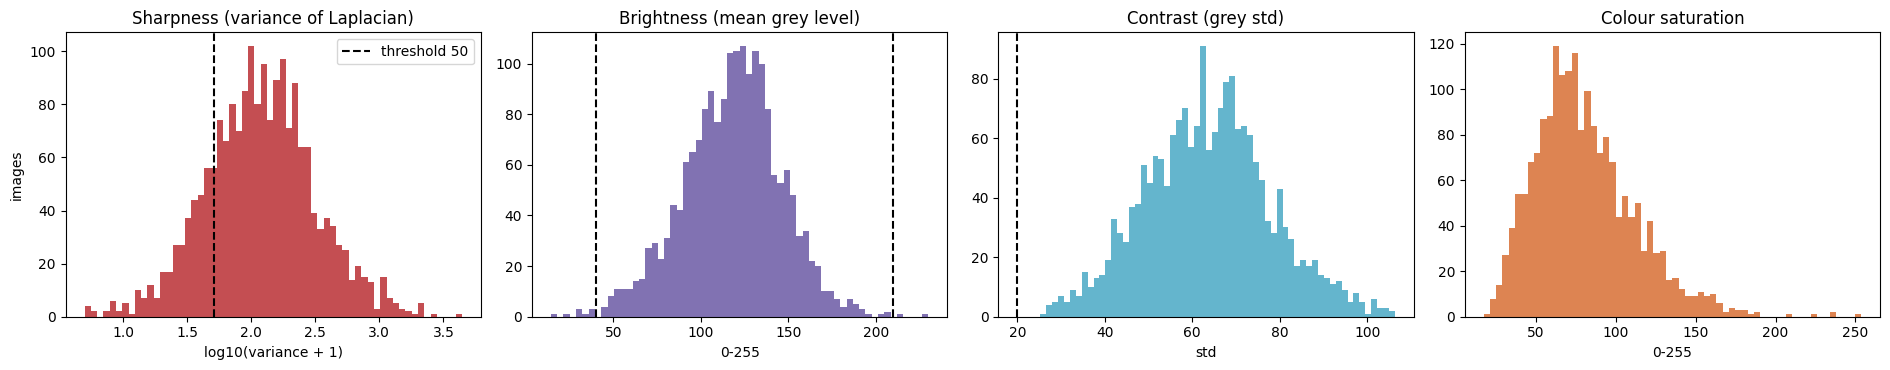

sharpness percentiles: {0.01: 10.0, 0.05: 23.8, 0.25: 60.5, 0.5: 117.5}


In [39]:
# CELL 39: Charts: sharpness, brightness, contrast and colour
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
# sharpness on a log scale; left of the dashed line = flagged blurry
axes[0].hist(np.log10(ok.blur + 1), bins=60, color='#C44E52')
axes[0].axvline(np.log10(BLUR_THR + 1), color='k', ls='--', label=f'threshold {BLUR_THR:g}')
axes[0].set(title='Sharpness (variance of Laplacian)', xlabel='log10(variance + 1)', ylabel='images')
axes[0].legend()
# brightness; outside the two dashed lines = too dark / too bright
axes[1].hist(ok.brightness, bins=60, color='#8172B2')
for t in (DARK, BRIGHT):
    axes[1].axvline(t, color='k', ls='--')
axes[1].set(title='Brightness (mean grey level)', xlabel='0-255')
# contrast; left of the dashed line = low contrast
axes[2].hist(ok.contrast, bins=60, color='#64B5CD')
axes[2].axvline(LOW_CONTRAST, color='k', ls='--')
axes[2].set(title='Contrast (grey std)', xlabel='std')
# colour strength; values near 0 are grey / black-and-white images
axes[3].hist(ok.saturation, bins=60, color='#DD8452')
axes[3].set(title='Colour saturation', xlabel='0-255')
savefig('B2_quality_distributions')

# low percentiles of sharpness, quoted in the summary
blur_pct = ok.blur.quantile([0.01, 0.05, 0.25, 0.5]).round(1)
print('sharpness percentiles:', blur_pct.to_dict())

**Explanation of Cell 39: Charts: sharpness, brightness, contrast and colour**

- **Purpose:** show where the thresholds sit in the real distributions.
- **What to check:** a threshold inside a big peak would flag half the dataset; it should sit in the low tail.
- **Variable:** `blur_pct`. **Saved as:** `B2_quality_distributions.png`.

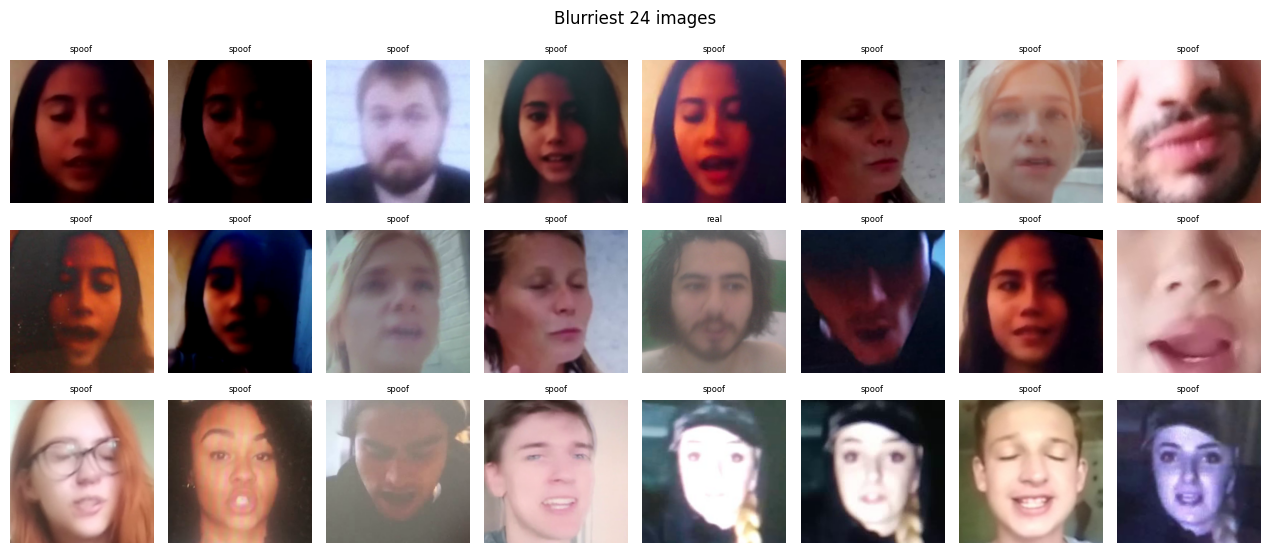

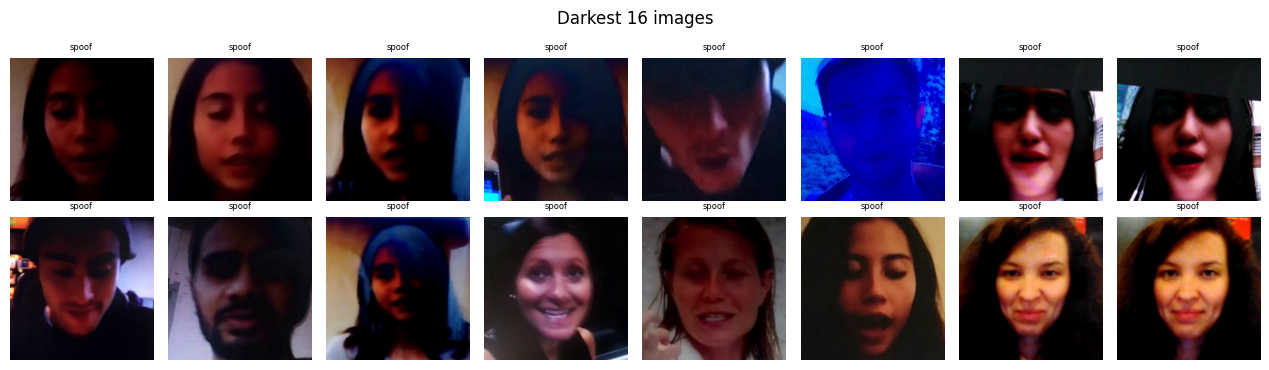

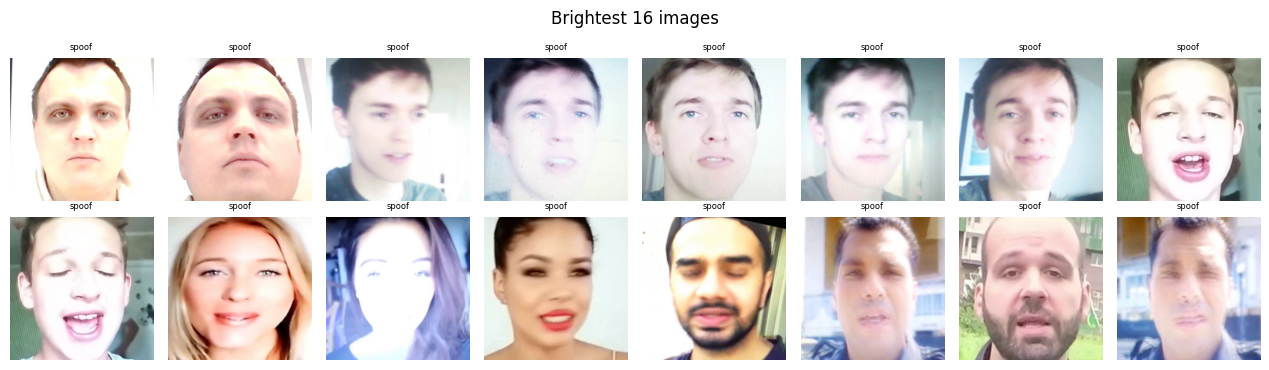

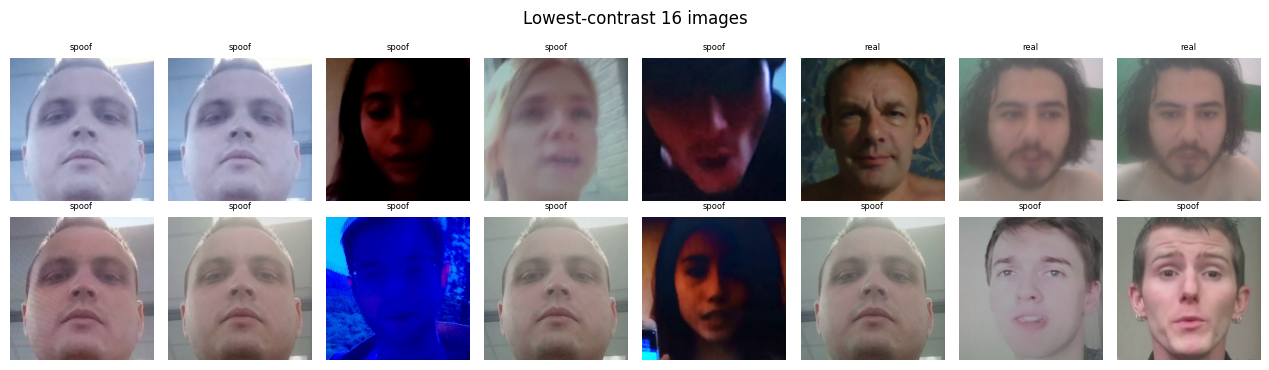

In [40]:
# CELL 40: Sample grids of the extreme images
# look at the extremes: a number cannot tell if a "dark" image is still a usable face
show_grid(ok.nsmallest(24, 'blur').path, 'Blurriest 24 images', 'B2_grid_blurriest', labels=ok.nsmallest(24, 'blur').cls)
show_grid(ok.nsmallest(16, 'brightness').path, 'Darkest 16 images', 'B2_grid_darkest', labels=ok.nsmallest(16, 'brightness').cls)
show_grid(ok.nlargest(16, 'brightness').path, 'Brightest 16 images', 'B2_grid_brightest', labels=ok.nlargest(16, 'brightness').cls)
show_grid(ok.nsmallest(16, 'contrast').path, 'Lowest-contrast 16 images', 'B2_grid_low_contrast', labels=ok.nsmallest(16, 'contrast').cls)

**Explanation of Cell 40: Sample grids of the extreme images**

- **Purpose:** inspect the extreme images by eye. The caption shows the class of each image.
- **What to check:** if the worst images are still clear faces, the thresholds are too strict. If they are blank or contain no face, they should be removed. Also note which class dominates each grid.
- **Saved as:** `B2_grid_blurriest.png`, `B2_grid_darkest.png`, `B2_grid_brightest.png`, `B2_grid_low_contrast.png`.

## 2.3 Real versus spoof

In [41]:
# CELL 41: Compare real and spoof images
# average of every measurement, separately for real and spoof
FEATURES = ['blur', 'brightness', 'contrast', 'saturation', 'bytes_per_pixel', 'width', 'height']
compare = ok.groupby('cls')[FEATURES].median().round(2).T      # median is robust to a few extreme images
compare['difference (spoof - real)'] = (compare['spoof'] - compare['real']).round(2)
compare.to_csv(OUT / 'real_vs_spoof_medians.csv')
compare

cls,real,spoof,difference (spoof - real)
blur,179.03,110.91,-68.12
brightness,109.32,120.78,11.46
contrast,56.56,64.52,7.96
saturation,78.92,75.38,-3.54
bytes_per_pixel,0.97,0.96,-0.01
width,523.00,488.00,-35.00
height,523.00,488.00,-35.00


**Explanation of Cell 41: Compare real and spoof images**

- **Purpose:** compare the typical (median) real image with the typical spoof image.
- **Rows:** sharpness, brightness, contrast, saturation, file bytes per pixel, width and height.
- **What to check:** large differences are not automatically bad (a recaptured screen is expected to be less sharp), but they show what a model could use. The next cells measure how easily each measurement alone separates the classes.
- **File:** `real_vs_spoof_medians.csv`.

In [42]:
# CELL 42: Function: auc_score
def auc_score(x, y):
    # AUC = chance that a random positive image has a larger value than a random negative image
    # 0.5 = the measurement says nothing, 1.0 or 0.0 = it separates the classes perfectly
    r = pd.Series(x).rank().values                       # rank of every value (ties get the average rank)
    n_pos, n_neg = int((y == 1).sum()), int((y == 0).sum())
    if n_pos == 0 or n_neg == 0:
        return np.nan
    return (r[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

**Explanation of Cell 42: Function: auc_score**

- **Purpose:** measure how well ONE simple number (for example sharpness) separates real from spoof images, without training any model.
- **Arguments:** `x` the measurement for every image, `y` the labels (1 = real, 0 = spoof).
- **Returns:** the AUC. 0.5 = no separation; above 0.5 = real images have larger values; below 0.5 = real images have smaller values.
- **Output:** none (defines the function only).

In [43]:
# CELL 43: Shortcut check: how well can one simple number separate the classes?
y_tr = ok[ok.split == 'train'].label.values
rows_auc = []
for f in FEATURES:
    a = auc_score(ok[ok.split == 'train'][f].values, y_tr)
    rows_auc.append({'feature': f, 'AUC (train)': round(a, 3),
                     'separability': round(max(a, 1 - a), 3)})   # direction does not matter, only distance from 0.5
shortcut = pd.DataFrame(rows_auc).sort_values('separability', ascending=False).reset_index(drop=True)
shortcut['shortcut risk'] = np.where(shortcut.separability >= SHORTCUT_AUC, 'HIGH', 'low')
shortcut.to_csv(OUT / 'shortcut_check.csv', index=False)
shortcut

,feature,AUC (train),separability,shortcut risk
0,contrast,0.328,0.672,low
1,saturation,0.655,0.655,low
2,blur,0.642,0.642,low
3,brightness,0.373,0.627,low
4,bytes_per_pixel,0.438,0.562,low
5,width,0.559,0.559,low
6,height,0.559,0.559,low


**Explanation of Cell 43: Shortcut check: how well can one simple number separate the classes?**

- **Purpose:** the most important anti-spoofing check. If a trivial measurement such as image width or file size already separates real from spoof, a neural network will happily use it, reach a high validation score, and then fail on images from a different camera.
- **Columns:** `AUC (train)` (direction included), `separability` (distance from chance; 0.5 = none, 1.0 = perfect), `shortcut risk` (`HIGH` when `separability` is at least `SHORTCUT_AUC`).
- **How to react to a HIGH row:** resize and centre-crop all images to one size, re-encode them in one format, and add augmentation for that property (blur, brightness, JPEG compression). Never feed raw size or file-size information to the model.
- **File:** `shortcut_check.csv`.

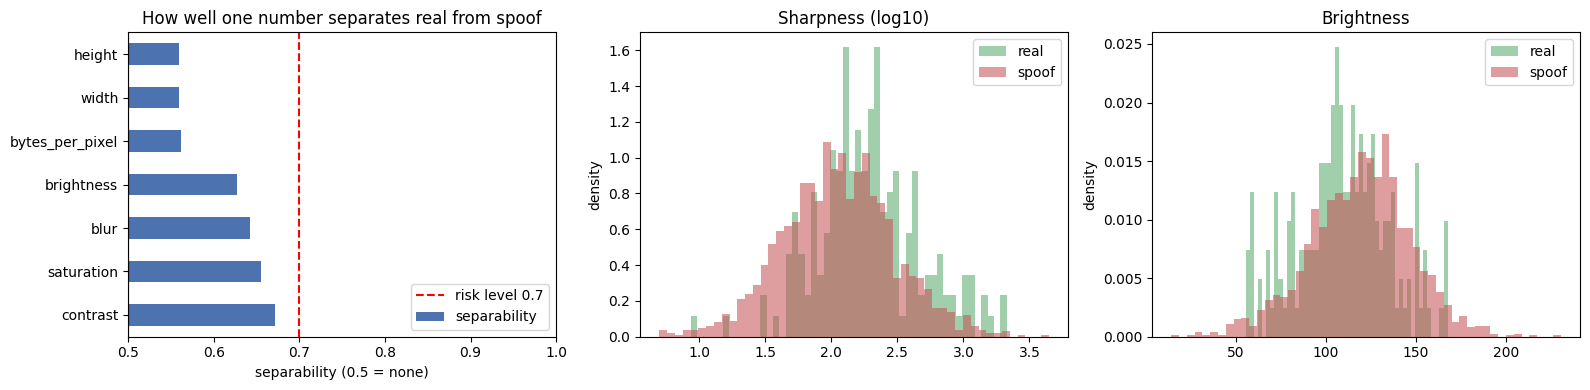

In [44]:
# CELL 44: Chart: shortcut check and real-versus-spoof distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
# left: separability of each simple feature (bars above the red line are shortcut risks)
shortcut.set_index('feature').separability.plot.barh(ax=axes[0], color='#4C72B0')
axes[0].axvline(SHORTCUT_AUC, color='r', ls='--', label=f'risk level {SHORTCUT_AUC}')
axes[0].axvline(0.5, color='k', lw=0.8)
axes[0].set(title='How well one number separates real from spoof', xlabel='separability (0.5 = none)', xlim=(0.5, 1), ylabel='')
axes[0].legend(loc='lower right')
# middle and right: sharpness and brightness of the two classes drawn on top of each other
for ax, f, ttl in ((axes[1], 'blur', 'Sharpness (log10)'), (axes[2], 'brightness', 'Brightness')):
    for cls, colour in (('real', '#55A868'), ('spoof', '#C44E52')):
        v = ok[ok.cls == cls][f]
        v = np.log10(v + 1) if f == 'blur' else v
        ax.hist(v, bins=50, alpha=0.55, density=True, color=colour, label=cls)
    ax.set(title=ttl, ylabel='density')
    ax.legend()
savefig('B3_real_vs_spoof')

**Explanation of Cell 44: Chart: shortcut check and real-versus-spoof distributions**

- **Purpose:** show the shortcut check as a picture.
- **Left:** one bar per measurement; bars that pass the red dashed line are a shortcut risk.
- **Middle and right:** sharpness and brightness of real and spoof images drawn on top of each other. The more the two shapes overlap, the less the measurement helps.
- **Saved as:** `B3_real_vs_spoof.png`.

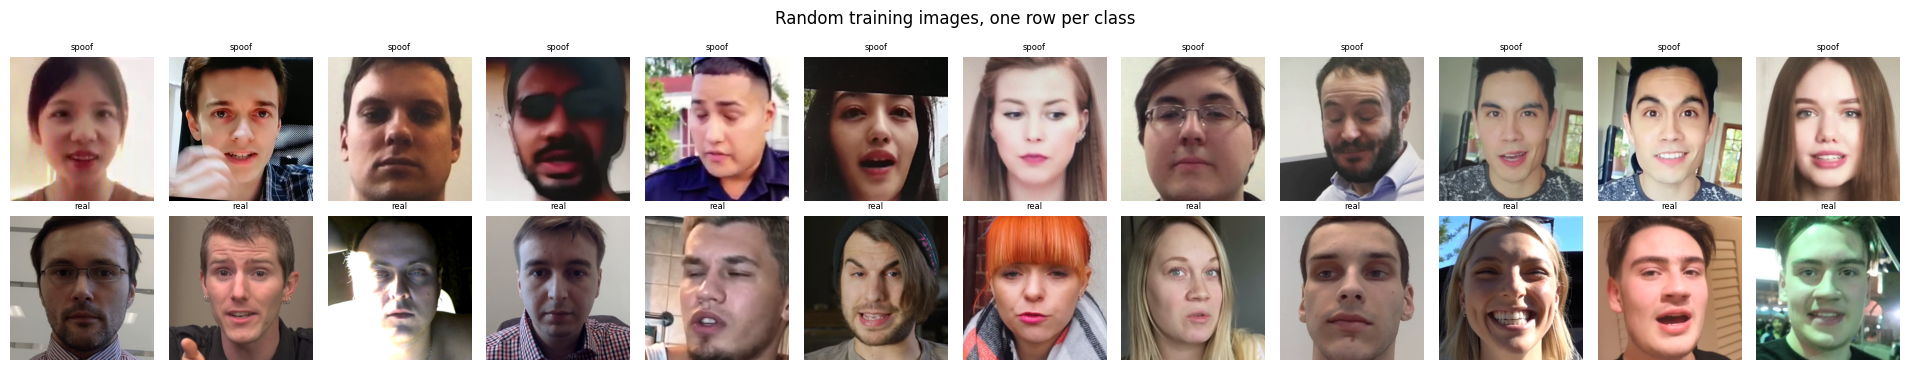

In [45]:
# CELL 45: Sample images of every class
# one row of N images per class, so each class can be judged by eye
paths, caps = [], []
for cls in LABEL_MAP:
    part = ok[(ok.split == 'train') & (ok.cls == cls)]
    pick = part.sample(min(N_PER_CLASS_GRID, len(part)), random_state=SEED)
    paths += list(pick.path)
    caps += [cls] * len(pick)
show_grid(paths, 'Random training images, one row per class', 'B3_samples_per_class',
          ncols=N_PER_CLASS_GRID, labels=caps)

**Explanation of Cell 45: Sample images of every class**

- **Purpose:** look at what each class really contains. This is the most useful check in this notebook.
- **Output:** one row per class in the order of `LABEL_MAP` (spoof first, then real).
- **What to check:** what makes the spoof images different (screen frame, reflections, moire patterns, borders, hands holding a phone)? Spoofs with a visible frame or border can be detected too easily and teach the model a border detector instead of liveness. Also check whether some "real" images look like a recapture.
- **Saved as:** `B3_samples_per_class.png`.

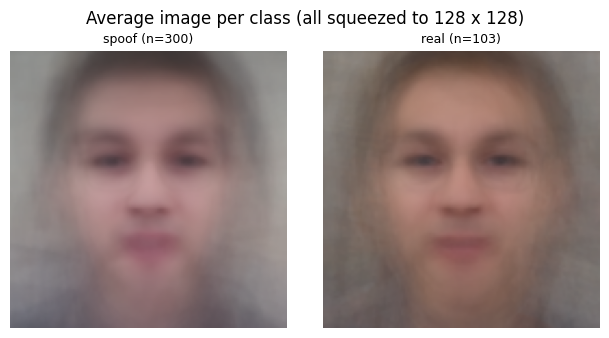

In [46]:
# CELL 46: Average image of every class
# average several images of one class pixel by pixel; things that are always in the same place stay sharp
fig, axes = plt.subplots(1, len(LABEL_MAP), figsize=(len(LABEL_MAP) * 3.2, 3.4))
for ax, cls in zip(axes, LABEL_MAP):
    part = ok[(ok.split == 'train') & (ok.cls == cls)]
    pick = part.sample(min(N_MEAN_IMAGE, len(part)), random_state=SEED)
    stack = []
    for p in pick.path:
        try:
            stack.append(np.asarray(Image.open(p).convert('RGB').resize((128, 128)), dtype=np.float32))
        except Exception:
            pass                                         # skip an unreadable file
    ax.imshow(np.mean(stack, axis=0).astype(np.uint8))   # the average image
    ax.set_title(f'{cls} (n={len(stack)})', fontsize=9)
    ax.axis('off')
fig.suptitle('Average image per class (all squeezed to 128 x 128)')
savefig('B3_mean_image_per_class')

**Explanation of Cell 46: Average image of every class**

- **Purpose:** show the typical image of each class. Every image is squeezed to 128 x 128 before averaging.
- **What to check:** a face-shaped blob in the centre means faces are roughly aligned in both classes. A visible frame, border or colour cast in one class shows a systematic difference the model could use as a shortcut.
- **Saved as:** `B3_mean_image_per_class.png`.

## 2.4 People, cameras and videos

This section uses the **file names only**, so it covers every image even when the quality scan covers only a sample.

In [47]:
# CELL 47: People, videos and images per split and class
# one row per (split, class): images, different people, different videos (clips)
people = img_df.groupby(['split', 'cls']).agg(
    images=('path', 'size'),
    people=('person', 'nunique'),
    videos=('clip', 'nunique')).reindex(list(SPLITS), level=0)
people['images per video'] = (people.images / people.videos).round(1)
people.to_csv(OUT / 'people_and_videos.csv')
people

images  people  videos  images per video
split cls                                            
train real     1223     110     133               9.2
      spoof    7076     104     859               8.2
val   real      405      27      42               9.6
      spoof    2543       9     300               8.5
test  real      314       0       1             314.0
      spoof    7266       0       1            7266.0

**Explanation of Cell 47: People, videos and images per split and class**

- **Purpose:** how many different people and videos stand behind the images.
- **Why it matters:** the images of one video are almost the same picture many times, so the **effective** size of the dataset is closer to the number of videos than to the number of images. The model also needs many different people, not many frames of the same few people.
- **File:** `people_and_videos.csv`.

In [48]:
# CELL 48: Sources and attack devices
# where the images come from (real and spoof) and which devices were used to attack (spoof only)
sources = pd.crosstab(img_df.source.fillna('unknown'), img_df.split).reindex(columns=list(SPLITS))
devices = (img_df[img_df.cls == 'spoof'].groupby(['split', 'device']).size()
           .rename('images').reset_index().sort_values('images', ascending=False))
sources.to_csv(OUT / 'sources.csv')
devices.to_csv(OUT / 'attack_devices.csv', index=False)
print('different attack-device combinations:', devices.device.nunique())
display(sources)
devices.head(10)

different attack-device combinations: 108


split,train,val,test
source,,,
AA5742,7,0,0
AAE5573GP98K,3,0,0
AGL752VM,0,10,0
FT1080P,10,0,0
FT720P,1445,1071,0
HTCD620,10,0,0
HUAWEIP7L,10,0,0
IPHONE8B,40,30,0
LTC270,20,0,0


,split,device,images
46,train,IIYAMAXB_SMG955U,1161
74,train,MBP1314_IPHONE8F,301
73,train,MBP1314_IPHONE8B,222
50,train,IIYAMAXU_MOTOMC_S0,209
51,train,IIYAMAXU_MOTOMC_S1,206
67,train,MBA1315_SMG955U_S0,190
52,train,IIYAMAXU_SMG955U_S0,147
93,train,SSM2433_S4508,132
72,train,MBP1314_IPHONE7F,124
164,val,MBP1314_IPHONE8F,113


**Explanation of Cell 48: Sources and attack devices**

- **Purpose:** list the sources of the videos and the attack devices (screen model and recording phone) named in the spoof file names.
- **What to check:** if the attack devices in the test split are also in training, the test score measures only known devices. A good liveness test uses devices the model never saw. If all images have one source, results may not transfer to other cameras.
- **Files:** `sources.csv`, `attack_devices.csv`.

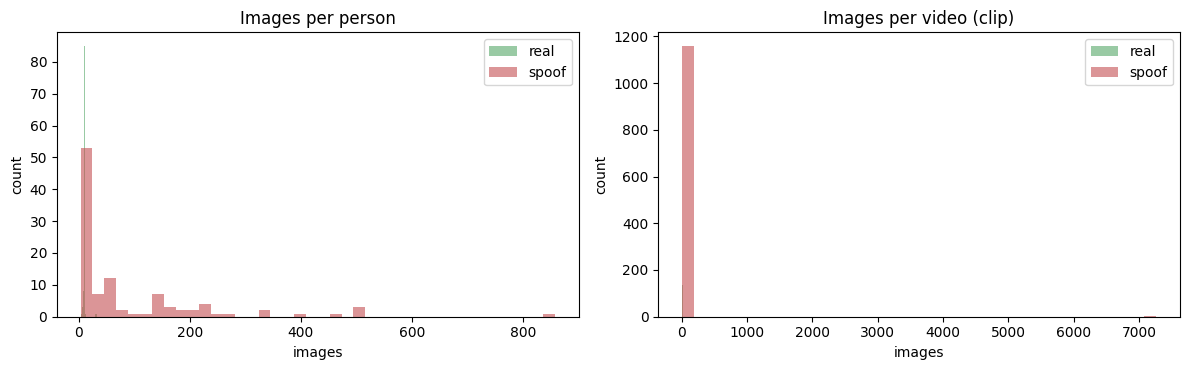

In [49]:
# CELL 49: Chart: images per person and per video
per_person = img_df.groupby(['cls', 'person']).size().rename('images').reset_index()
per_video = img_df.groupby(['cls', 'clip']).size().rename('images').reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, d, ttl in ((axes[0], per_person, 'Images per person'), (axes[1], per_video, 'Images per video (clip)')):
    for cls, colour in (('real', '#55A868'), ('spoof', '#C44E52')):
        ax.hist(d[d.cls == cls].images, bins=40, alpha=0.6, color=colour, label=cls)
    ax.set(title=ttl, xlabel='images', ylabel='count')
    ax.legend()
savefig('B4_people_and_videos')

**Explanation of Cell 49: Chart: images per person and per video**

- **Purpose:** show whether a few people or videos dominate the data.
- **What to check:** a long tail to the right means a few people or videos contribute very many frames. Such people can dominate training, and the model may memorise them. Consider capping the number of frames per video.
- **Saved as:** `B4_people_and_videos.png`.

## 2.5 Duplicates and label noise

- **Exact duplicates**: identical file bytes (same MD5). **Near duplicates**: identical perceptual hash.
- Neighbouring frames of one video are naturally almost identical, so they form `same video` groups. They are expected and are **not** errors, but they reduce the effective dataset size.
- The same picture under **both labels** (real and spoof) is a clear **labelling conflict**.
- The same picture **across splits** is **leakage** (section 2.6).

In [50]:
# CELL 50: Function: dup_groups
def dup_groups(df, key):
    # keep only rows whose hash appears more than once
    sizes = df.groupby(key).path.transform('size')
    d = df[sizes > 1].copy()
    if d.empty:
        return d.assign(group_type=pd.Series(dtype=str))
    # how many splits / classes / videos does each duplicate group touch?
    agg = d.groupby(key).agg(n_splits=('split', 'nunique'), n_classes=('cls', 'nunique'), n_clips=('clip', 'nunique'))
    d = d.join(agg, on=key)
    d['group_type'] = np.select(
        [d.n_classes > 1, d.n_splits > 1, d.n_clips == 1],   # label conflict first: it is the most serious finding
        ['real and spoof (label conflict)', 'across splits', 'same video (neighbouring frames)'],
        'same class, different videos')
    return d.sort_values([key, 'split'])

**Explanation of Cell 50: Function: dup_groups**

- **Purpose:** find images sharing a hash and label each group:
  - `same video (neighbouring frames)`: copies from one video; harmless but they add no new information;
  - `same class, different videos`: the same picture appears in two videos of the same class;
  - `real and spoof (label conflict)`: the same picture carries both labels, so at least one is wrong;
  - `across splits`: **data leakage** between splits (groups that are also label conflicts are counted as conflicts; the leakage tables in section 2.6 count every shared image regardless).
- **Arguments:** `df` scanned images, `key` = `'md5'` or `'phash'`.
- **Output:** none (defines the function only).

In [51]:
# CELL 51: Find exact duplicates
exact = dup_groups(ok, 'md5')                         # identical files
exact.to_csv(OUT / 'duplicates_exact.csv', index=False)
print(f'{len(exact):,} images belong to {exact.md5.nunique() if len(exact) else 0} exact-duplicate groups')

0 images belong to 0 exact-duplicate groups


**Explanation of Cell 51: Find exact duplicates**

- **Purpose:** find identical files (same MD5).
- **Variable:** `exact`. **File:** `duplicates_exact.csv` (every image in a duplicate group, so the team can open them).

In [52]:
# CELL 52: Find near duplicates
# search only images that are NOT already exact duplicates, so nothing is counted twice
near = dup_groups(ok[~ok.md5.isin(exact.md5)], 'phash')
near.to_csv(OUT / 'duplicates_near.csv', index=False)
print(f'{len(near):,} images belong to {near.phash.nunique() if len(near) else 0} near-duplicate groups')

85 images belong to 34 near-duplicate groups


**Explanation of Cell 52: Find near duplicates**

- **Purpose:** find re-encoded, resized or neighbouring-frame copies (same perceptual hash). Check some groups by eye.
- **Variable:** `near`. **File:** `duplicates_near.csv`.
- **Note:** with a sample scan (below 100%) most neighbouring frames are not in the sample, so this count is a lower bound.

In [53]:
# CELL 53: Duplicate summary table
dup_summary = pd.DataFrame({
    'exact (md5)': exact.groupby('group_type').md5.nunique() if len(exact) else pd.Series(dtype=int),
    'near (pHash)': near.groupby('group_type').phash.nunique() if len(near) else pd.Series(dtype=int),
}).fillna(0).astype(int)
dup_summary.index.name = 'duplicate groups'
dup_summary.to_csv(OUT / 'duplicate_summary.csv')
dup_summary

,exact (md5),near (pHash)
duplicate groups,,
across splits,0,2
real and spoof (label conflict),0,3
"same class, different videos",0,11
same video (neighbouring frames),0,18


**Explanation of Cell 53: Duplicate summary table**

- **Purpose:** number of duplicate groups of each type.
- **What to check:** `across splits` should be 0 and `real and spoof (label conflict)` should be 0. Anything else needs a decision.
- **Note:** with `SCAN_FRACTION` below 1 the real numbers are higher.

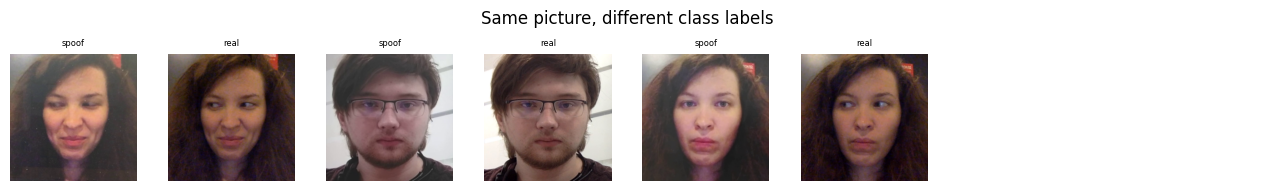

In [54]:
# CELL 54: Grid: images with conflicting labels
# show images that appear as both real and spoof (the caption shows the class each copy carries)
conflict = pd.concat([exact, near]) if len(exact) or len(near) else exact
conflict = conflict[conflict.group_type == 'real and spoof (label conflict)'] if len(conflict) else conflict
if len(conflict):
    sel = conflict.head(24)
    show_grid(sel.path, 'Same picture, different class labels', 'B5_label_conflicts', labels=sel.cls)
else:
    print('no label conflicts found among the scanned images')

**Explanation of Cell 54: Grid: images with conflicting labels**

- **Purpose:** look at the label conflicts directly.
- **Output:** a grid of up to 24 images; the caption is the class each copy carries. The same picture with both captions proves that at least one label is wrong.
- **Saved as:** `B5_label_conflicts.png` (only when conflicts exist).

## 2.6 Leakage between splits

**Data leakage** means that something the model must be tested on has already been seen during training. For liveness there are two forms: the same **picture** (or an almost identical frame) in two splits, and the same **person** in two splits. A model that has seen a person's face in training will find that person easier in the test, and the score will look better than it really is.

In [55]:
# CELL 55: Function: overlap_matrix
def overlap_matrix(df, key, groups):
    # for every pair of groups, count how many distinct values of `key` (hash, person, ...) they share
    sets = {s: set(df[df.split == s][key].dropna()) for s in groups}
    return pd.DataFrame([[len(sets[a] & sets[b]) if a != b else np.nan for b in groups] for a in groups],
                        index=groups, columns=groups)

**Explanation of Cell 55: Function: overlap_matrix**

- **Purpose:** count how many images, people or videos two splits have in common.
- **Arguments:** `df` the table, `key` = `'md5'`, `'phash'`, `'person'` or `'clip'`, `groups` split names.
- **Returns:** a square table; the diagonal is empty.
- **Output:** none (defines the function only).

In [56]:
# CELL 56: Identical images shared between splits (MD5)
leak_exact = overlap_matrix(ok, 'md5', list(SPLITS))
leak_exact.to_csv(OUT / 'leakage_exact_image_overlap.csv')
leak_exact

,train,val,test
train,NaN,0.0,0.0
val,0.0,NaN,0.0
test,0.0,0.0,NaN


**Explanation of Cell 56: Identical images shared between splits (MD5)**

- **Purpose:** do two splits share any identical picture?
- **What to check:** every number should be **0**. A positive number means images were seen in two splits.
- **File:** `leakage_exact_image_overlap.csv`.

In [57]:
# CELL 57: Near-identical images shared between splits (pHash)
leak_near = overlap_matrix(ok, 'phash', list(SPLITS))
leak_near.to_csv(OUT / 'leakage_near_image_overlap.csv')
leak_near

,train,val,test
train,NaN,4.0,0.0
val,4.0,NaN,0.0
test,0.0,0.0,NaN


**Explanation of Cell 57: Near-identical images shared between splits (pHash)**

- **Purpose:** the same check for near copies (includes the identical ones).
- **File:** `leakage_near_image_overlap.csv`.
- **Note:** with `SCAN_FRACTION` below 1 only scanned images are compared, so real overlap is larger.

In [58]:
# CELL 58: People shared between splits
# uses the file names, so it covers EVERY image, not only the scanned sample
leak_people = overlap_matrix(img_df, 'person', list(SPLITS))
leak_people.to_csv(OUT / 'leakage_people_overlap.csv')
print('people per split:', img_df.groupby('split').person.nunique().reindex(list(SPLITS)).to_dict())
leak_people

people per split: {'train': 122, 'val': 27, 'test': 0}


,train,val,test
train,NaN,9.0,0.0
val,9.0,NaN,0.0
test,0.0,0.0,NaN


**Explanation of Cell 58: People shared between splits**

- **Purpose:** do the same people appear in more than one split? The person is read from the file name (source and person number).
- **What to check:** for an honest test every number should be **0**: the model is tested on people it never saw. A positive number is leakage by identity.
- **Caution:** person numbers are only meaningful if the dataset authors numbered people **globally**. If the same number can appear in different sources or sessions for different people, small overlaps may be coincidences; compare a few of the shared people by eye.
- **File:** `leakage_people_overlap.csv`.

In [59]:
# CELL 59: Real and spoof images of the same person
# for every split: how many people appear both as real and as spoof images?
real_people = img_df[img_df.cls == 'real'].groupby('split').person.apply(set)
spoof_people = img_df[img_df.cls == 'spoof'].groupby('split').person.apply(set)
both = pd.DataFrame({
    'people with real images': {s: len(real_people.get(s, set())) for s in SPLITS},
    'people with spoof images': {s: len(spoof_people.get(s, set())) for s in SPLITS},
    'people with both': {s: len(real_people.get(s, set()) & spoof_people.get(s, set())) for s in SPLITS},
})
both.to_csv(OUT / 'people_real_and_spoof.csv')
both

,people with real images,people with spoof images,people with both
train,110,104,92
val,27,9,9
test,1,1,1


**Explanation of Cell 59: Real and spoof images of the same person**

- **Purpose:** check whether a person's real face and spoofs of the same person are both present in a split.
- **Why it matters:** if every spoof is paired with a real video of the same person, the model must compare the *medium* (live versus recaptured), which is what we want. If real and spoof people are completely different, the model could learn to recognise the people instead.
- **File:** `people_real_and_spoof.csv`.

## 2.7 Summary and handoff

The cells below build a plain-text summary (`EDA_summary.md`), an HTML report and copy everything to Google Drive.

In [60]:
# CELL 60: Summary: dataset size and balance
n_split = img_df.split.value_counts().reindex(list(SPLITS)).fillna(0).astype(int)
lines = [                                                  # `lines` collects one text line per finding
    '# Anti-spoofing EDA: summary', '',
    '## Dataset size',
    '- ' + '; '.join(f"{s}: {fmt_int(n_split[s])} images" for s in SPLITS) + '. The validation split is official (development).',
    '- Classes: ' + ', '.join(f'{k} ({v})' for k, v in LABEL_MAP.items()) + '.',
    '', '## Class balance',
    f"- Training: {imbalance['largest class']} versus {imbalance['smallest class']}; imbalance ratio {imbalance['largest / smallest (imbalance ratio)']}.",
    f"- Spoof share per split: " + ', '.join(f"{s} {share.loc[s, 'spoof']}%" for s in SPLITS) + '.',
]
print(len(lines), 'lines so far')

9 lines so far


**Explanation of Cell 60: Summary: dataset size and balance**

- **Purpose:** start the written summary from the tables above, so nobody retypes numbers.
- **Variable:** `lines`, a list with one text line per finding. Later summary cells add to it.
- **If it fails with `NameError`:** a cell above was not run; the error names it.

In [61]:
# CELL 61: Summary: image quality, shortcuts and duplicates
lines += ['', '## Image properties and quality']
lines.append(f"- Scan coverage: {SCAN_FRACTION:.0%} of the images.")
lines.append(f"- Different image sizes: {fmt_int(size_counts['size'].nunique())}; most common: "
             + ', '.join(f'{k} ({fmt_int(v)})' for k, v in size_counts.groupby('size').images.sum().sort_values(ascending=False).head(3).items()) + '.')
lines.append('- Formats / modes: ' + ', '.join(f'{f} {m} ({fmt_int(cnt)})' for (f, m), cnt in
             ok.groupby(['format', 'mode']).size().items()) + '.')
tot = quality_split.sum()                                  # flags summed over all splits
lines.append(f"- Flags: {fmt_int(tot.corrupted)} corrupted, {fmt_int(tot.low_res)} low-resolution (<{LOW_RES_PX}px), "
             f"{fmt_int(tot.blurry)} blurry (Laplacian variance <{BLUR_THR:g}), {fmt_int(tot.too_dark)} too dark, "
             f"{fmt_int(tot.too_bright)} too bright, {fmt_int(tot.low_contrast)} low contrast.")
lines.append(f"- Sharpness percentiles (1st, 5th, 25th, 50th): {', '.join(str(v) for v in blur_pct.values)}.")

lines += ['', '## Real versus spoof (shortcut check)']
risky = shortcut[shortcut['shortcut risk'] == 'HIGH']
if len(risky):
    lines.append('- SHORTCUT RISK: ' + ', '.join(f'{r.feature} ({r.separability})' for r in risky.itertuples())
                 + f' separate real from spoof at AUC >= {SHORTCUT_AUC}.')
else:
    lines.append(f'- No single simple measurement separates real from spoof above AUC {SHORTCUT_AUC}; strongest: '
                 f'{shortcut.iloc[0].feature} ({shortcut.iloc[0].separability}).')
print(len(lines), 'lines so far')

19 lines so far


**Explanation of Cell 61: Summary: image quality, shortcuts and duplicates**

- **Purpose:** add scan coverage, sizes, formats, quality flags, sharpness percentiles and the shortcut-check result to `lines`.

In [62]:
# CELL 62: Summary: people, duplicates and leakage
lines += ['', '## People, cameras and videos']
lines.append(f"- {fmt_int(img_df.person.nunique())} different people and {fmt_int(img_df['clip'].nunique())} videos "
             f"behind {fmt_int(len(img_df))} images (about {len(img_df) / max(img_df['clip'].nunique(), 1):.0f} images per video).")
lines.append(f"- Attack-device combinations: {fmt_int(devices.device.nunique())}; sources: {', '.join(sources.index.astype(str))}.")

lines += ['', '## Duplicates, leakage and label noise']
lines.append(f"- Duplicate groups: {fmt_int(exact.md5.nunique() if len(exact) else 0)} exact, "
             f"{fmt_int(near.phash.nunique() if len(near) else 0)} near-duplicate.")
n_leak = int(np.nansum(leak_exact.values) // 2)
n_leak_near = int(np.nansum(leak_near.values) // 2)
if n_leak or n_leak_near:
    lines.append(f"- IMAGE LEAKAGE: {n_leak} identical and {n_leak_near} near-identical images are shared between splits.")
else:
    lines.append('- No identical or near-identical images are shared between splits.')
n_ppl = int(np.nansum(leak_people.values) // 2)
if n_ppl:
    lines.append(f"- PEOPLE LEAKAGE: {fmt_int(n_ppl)} person identifiers appear in more than one split (see leakage_people_overlap.csv).")
else:
    lines.append('- No person appears in more than one split.')
n_conf = exact[exact.group_type == 'real and spoof (label conflict)'].md5.nunique() if len(exact) else 0
lines.append(f"- Label conflicts (same picture as real and spoof): {fmt_int(n_conf)} exact groups.")
print(len(lines), 'lines so far')

29 lines so far


**Explanation of Cell 62: Summary: people, duplicates and leakage**

- **Purpose:** add people and videos, duplicates, image leakage, people leakage and label conflicts.
- **Reading the numbers:** the person-leakage count is a count of person identifiers shared between splits (a pair of splits sharing 5 people adds 5).

In [63]:
# CELL 63: Summary: suggested rules, then write EDA_summary.md
lines += ['', '## Suggested cleaning and training rules (for team decision)',
          '- Remove corrupted files listed in corrupted_files.csv.',
          '- Resize and crop every image to ONE input size and re-encode it the same way for both classes, so size and file format cannot be used as a shortcut.',
          '- Do not delete dark or blurry images automatically: they are normal in real attacks. Remove only blank or non-face images found in the extreme grids.',
          '- Remove images that appear in two splits and review images that carry both labels.',
          '- Use the official development split for validation and the evaluation split once, at the end.',
          f"- Use class weights (class_weights.csv) or balanced sampling (imbalance ratio {imbalance['largest / smallest (imbalance ratio)']}).",
          '- Report APCER, BPCER, ACER, AUC and EER, not accuracy alone, and choose the decision threshold on validation only.',
          '- Test on a camera or attack device that is not in training if possible (cross-device test).',
          '- Cap the number of frames taken from one video, and use augmentation: colour jitter, blur, JPEG compression, random crop.']

summary_text = '\n'.join(lines)
(OUT / 'EDA_summary.md').write_text(summary_text, encoding='utf-8')   # save to file
print(summary_text)

# Anti-spoofing EDA: summary

## Dataset size
- train: 8,299 images; val: 2,948 images; test: 7,580 images. The validation split is official (development).
- Classes: spoof (0), real (1).

## Class balance
- Training: spoof (7,076) versus real (1,223); imbalance ratio 5.79.
- Spoof share per split: train 85.3%, val 86.3%, test 95.9%.

## Image properties and quality
- Scan coverage: 10% of the images.
- Different image sizes: 673; most common: 400x400 (19), 401x401 (14), 480x480 (14).
- Formats / modes: PNG RGB (1,883).
- Flags: 0 corrupted, 1 low-resolution (<128px), 359 blurry (Laplacian variance <50), 9 too dark, 2 too bright, 0 low contrast.
- Sharpness percentiles (1st, 5th, 25th, 50th): 10.0, 23.8, 60.5, 117.5.

## Real versus spoof (shortcut check)
- No single simple measurement separates real from spoof above AUC 0.7; strongest: contrast (0.672).

## People, cameras and videos
- 140 different people and 1,335 videos behind 18,827 images (about 14 images per video).
- Attack-dev

**Explanation of Cell 63: Summary: suggested rules, then write EDA_summary.md**

- **Purpose:** finish the summary, save `EDA_summary.md` and print it.
- **Suggested rules** are **proposals for the team to approve**; nothing on Drive is modified.
- **Metric names:** APCER = share of spoofs accepted as real; BPCER = share of real faces rejected; ACER = their average; EER = error rate where APCER equals BPCER.
- **Output:** the full summary: read this first and paste it into the report.

In [64]:
# CELL 64: HTML helper: img_tag
def img_tag(name):
    p = OUT / f'{name}.png'
    if not p.exists():                       # a chart that was not produced
        return ''
    b64 = base64.b64encode(p.read_bytes()).decode()      # embed the PNG as text
    return f'<img src="data:image/png;base64,{b64}" style="max-width:100%;margin:8px 0">'

**Explanation of Cell 64: HTML helper: img_tag**

- **Purpose:** embed a saved chart PNG inside the HTML (base64), so the report is a **single file**.
- **Returns:** an `<img>` tag, or an empty string if the chart does not exist.
- **Output:** none (defines the function only).

In [65]:
# CELL 65: HTML helper: table
def table(df, title):
    # heading + the pandas table as HTML
    return f'<h3>{html.escape(title)}</h3>' + df.to_html(border=0, classes='t', na_rep='-')

**Explanation of Cell 65: HTML helper: table**

- **Purpose:** turn a pandas table into an HTML table with a heading.
- **Output:** none (defines the function only).

In [66]:
# CELL 66: HTML style (css)
css = ('body{font-family:Arial,sans-serif;max-width:980px;margin:24px auto;padding:0 16px}'
       'table.t{border-collapse:collapse;font-size:13px}table.t td,table.t th{border:1px solid #ccc;padding:3px 8px}'
       'th{background:#f1f1f1}')

**Explanation of Cell 66: HTML style (css)**

- **Purpose:** the page style (font, table borders). Edit here to change how the report looks.

In [67]:
# CELL 67: Convert the summary to HTML
# "# " -> h1, "## " -> h2, "- " -> list item
summary_html = ''.join(
    f'<h2>{html.escape(l[3:])}</h2>' if l.startswith('## ') else
    f'<h1>{html.escape(l[2:])}</h1>' if l.startswith('# ') else
    f'<li>{html.escape(l[2:])}</li>' if l.startswith('- ') else ''
    for l in summary_text.splitlines())
print(len(summary_html), 'characters of HTML')

2751 characters of HTML


**Explanation of Cell 67: Convert the summary to HTML**

- **Purpose:** convert the markdown-style summary lines into HTML headings and list items.
- **Variable:** `summary_html`.

In [68]:
# CELL 68: Choose the charts for the report
# charts (saved PNG names) shown at the end of the report, in this order
charts = ['A1_preview', 'B1_class_distribution', 'B2_quality_distributions', 'B2_grid_blurriest', 'B2_grid_darkest',
          'B3_real_vs_spoof', 'B3_samples_per_class', 'B3_mean_image_per_class', 'B4_people_and_videos', 'B5_label_conflicts']

**Explanation of Cell 68: Choose the charts for the report**

- **Purpose:** the list of charts in the report. To add a chart, save it with `savefig('name')` and add `'name'` here.

In [69]:
# CELL 69: Build the HTML report
sections = [
    summary_html,                                            # written summary first
    '<h2>Tables</h2>',
    table(counts, 'Images per split and class'),
    table(share, 'Share of each class within its split (%)'),
    table(imbalance.to_frame(), 'Class imbalance (train)'),
    table(class_weights, 'Class weights'),
    table(quality_split, 'Quality flags per split'),
    table(quality_class, 'Quality flags per class'),
    table(compare, 'Real versus spoof: median of each measurement'),
    table(shortcut, 'Shortcut check'),
    table(fmt_mode, 'Formats and colour modes'),
    table(people, 'People, videos and images per split and class'),
    table(sources, 'Sources (images per split)'),
    table(dup_summary, 'Duplicate groups'),
    table(leak_exact, 'Identical images shared between splits (MD5)'),
    table(leak_near, 'Near-identical images shared between splits (pHash)'),
    table(leak_people, 'People shared between splits'),
    table(both, 'Real and spoof images of the same person'),
    '<h2>Charts and sample images</h2>',
] + [img_tag(c) for c in charts]                             # then the charts

(OUT / 'EDA_report.html').write_text(
    f'<html><head><meta charset="utf-8"><style>{css}</style></head><body>' + ''.join(sections) + '</body></html>',
    encoding='utf-8')
print('wrote', OUT / 'EDA_report.html')

wrote eda_outputs/EDA_report.html


**Explanation of Cell 69: Build the HTML report**

- **Purpose:** assemble `EDA_report.html`: summary, then tables, then charts.
- **Output:** the report path. Open it from the Colab file browser, or from Drive after the next cell.

In [70]:
# CELL 70: Copy all outputs to Google Drive
if SAVE_TO is not None:
    SAVE_TO.mkdir(parents=True, exist_ok=True)
    for f in OUT.iterdir():
        shutil.copy(f, SAVE_TO / f.name)                    # copy every result file
    print('copied', len(list(OUT.iterdir())), 'files to', SAVE_TO)
sorted(p.name for p in OUT.iterdir())                        # list what was produced

copied 37 files to /content/drive/MyDrive/anti_spoofing_eda


['A1_preview.png',
 'B1_class_distribution.png',
 'B2_grid_blurriest.png',
 'B2_grid_brightest.png',
 'B2_grid_darkest.png',
 'B2_grid_low_contrast.png',
 'B2_quality_distributions.png',
 'B3_mean_image_per_class.png',
 'B3_real_vs_spoof.png',
 'B3_samples_per_class.png',
 'B4_people_and_videos.png',
 'B5_label_conflicts.png',
 'EDA_report.html',
 'EDA_summary.md',
 'attack_devices.csv',
 'class_imbalance.csv',
 'class_share_pct.csv',
 'class_weights.csv',
 'corrupted_files.csv',
 'duplicate_summary.csv',
 'duplicates_exact.csv',
 'duplicates_near.csv',
 'formats_and_modes.csv',
 'image_quality.csv',
 'image_sizes.csv',
 'label_map.csv',
 'leakage_exact_image_overlap.csv',
 'leakage_near_image_overlap.csv',
 'leakage_people_overlap.csv',
 'people_and_videos.csv',
 'people_real_and_spoof.csv',
 'quality_flags_by_class.csv',
 'quality_flags_by_split.csv',
 'real_vs_spoof_medians.csv',
 'shortcut_check.csv',
 'sources.csv',
 'spoof_inventory.csv']

**Explanation of Cell 70: Copy all outputs to Google Drive**

- **Purpose:** save the results outside Colab (files in `eda_outputs/` vanish when the session ends).
- **Where:** `My Drive/anti_spoofing_eda/`. Share this folder with the team.
- **Not on GitHub:** commit only this notebook (outputs cleared), never datasets, csv files or result images.

## Handoff to training

- The files the training notebook needs are `spoof_inventory.csv` (every image with its split, class, label, person and video), `label_map.csv` and `class_weights.csv`. The official validation split is the `val` value of the `split` column.
- Review `EDA_summary.md`, the shortcut check, the label-conflict grid and the leakage tables before training. Treat cleaning suggestions as proposals for the team to approve, not as changes already made.
- Filter training data only, never the validation or test splits.
- Report APCER, BPCER, ACER, AUC and EER, and say in the report which devices and people were in training and which were not.